# Hay cosas que he puesto para mi, para entenderlo bien de forma resumida y en texto :)

In [6]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os

OUTPUT_DIR = "/content/drive/MyDrive/Proyecto_IA/outputs/"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Carpeta de almacenamiento preparada:", OUTPUT_DIR)

Carpeta de almacenamiento preparada: /content/drive/MyDrive/Proyecto_IA/outputs/


In [8]:
import os

print("¿Existe la carpeta?", os.path.exists(OUTPUT_DIR))
print("Ruta:", OUTPUT_DIR)

¿Existe la carpeta? True
Ruta: /content/drive/MyDrive/Proyecto_IA/outputs/


# Fundamentos de LLMs con Hugging Face + introducción a LangChain

En este notebook vamos a aprender a **cargar, configurar, usar y adaptar** modelos de lenguaje pequeños con las librerías de Hugging Face (`transformers`, `datasets`, `peft`) y terminaremos con una **introducción práctica a LangChain**.

| # | Sección | Modelos |
|---|---------|---------|
| 0 | Preparación del entorno | – |
| 1 | Las tres familias de Transformers: qué sabe hacer cada una | [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased), [DistilBERT-SST2](https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english), [BERT-NER](https://huggingface.co/dslim/bert-base-NER), [MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), [SmolLM2-135M](https://huggingface.co/HuggingFaceTB/SmolLM2-135M), [Flan-T5-small](https://huggingface.co/google/flan-t5-small) |
| 2 | Adaptación al dominio (recetas de cocina) | [SmolLM2-135M](https://huggingface.co/HuggingFaceTB/SmolLM2-135M), [Flan-T5-small](https://huggingface.co/google/flan-t5-small), [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased) |
| 3 | Parámetros de generación y *chat templates* | [Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct) |
| 4 | Modelo con *instruction tuning* vs. modelo sin él | [T5-base](https://huggingface.co/google-t5/t5-base) vs [Flan-T5-base](https://huggingface.co/google/flan-t5-base), [SmolLM2-360M](https://huggingface.co/HuggingFaceTB/SmolLM2-360M) vs [SmolLM2-360M-Instruct](https://huggingface.co/HuggingFaceTB/SmolLM2-360M-Instruct) |
| 5 | Introducción a LangChain | LLM vía OpenRouter + [MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) (embeddings) |

> **Nota:** todos los modelos son **pequeños** (≤ 0.5B parámetros): funcionan en una GPU de ~6 GB o en Google Colab (GPU T4). En CPU también funcionan, pero el entrenamiento de la sección 2 será lento: activa `MODO_RAPIDO`.

Al final de cada sección hay una celda **Ejercicios**.

---
## 0. Preparación del entorno

Si estás en **Google Colab**, la siguiente celda instala las librerías necesarias. En local (entorno creado con `uv`, ver `README.md`) no hace nada.

In [9]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q -U transformers datasets accelerate peft evaluate sentencepiece sentence-transformers langchain langchain-openai langchain-huggingface python-dotenv
print("¿Estamos en Colab?", IN_COLAB)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
¿Estamos en Colab? True


In [10]:
!pip install torch torchvision torchaudio
%pip install transformers

In [11]:
import gc
import math
import os
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import logging as hf_logging

warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
pd.set_option("display.max_colwidth", None)

# Dispositivo: GPU NVIDIA (cuda), Apple Silicon (mps) o CPU
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

# bf16 solo en GPUs modernas (Ampere o superior: RTX 30xx/40xx, A100...). La T4 de Colab usa fp16.
USE_BF16 = device == "cuda" and torch.cuda.is_bf16_supported()
USE_FP16 = device == "cuda" and not USE_BF16
DTYPE_INFERENCIA = torch.bfloat16 if USE_BF16 else (torch.float16 if device == "cuda" else torch.float32)

SEED = 42
transformers.set_seed(SEED)

print(f"transformers {transformers.__version__} | torch {torch.__version__}")
print(f"Dispositivo: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))
print(f"bf16: {USE_BF16} | fp16: {USE_FP16}")

transformers 5.22.1 | torch 2.11.0+cu130
Dispositivo: cuda (Tesla T4)
bf16: True | fp16: False


Algunas **funciones auxiliares** que reutilizaremos en todo el notebook:

In [12]:
def contar_parametros(model):
    # Número de parámetros del modelo en millones
    return f"{model.num_parameters() / 1e6:.0f}M parámetros"


def liberar_memoria():
    # Libera la memoria de la GPU (llámala después de hacer `del model`)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        print(f"VRAM ocupada: {torch.cuda.memory_allocated() / 1e9:.2f} GB")


@torch.no_grad()
def generar(model, tok, prompt, **gen_kwargs):
    # Genera texto con un modelo decoder-only y devuelve SOLO el texto nuevo
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    gen_kwargs.setdefault("max_new_tokens", 60)
    gen_kwargs.setdefault("pad_token_id", tok.pad_token_id or tok.eos_token_id)
    out = model.generate(**inputs, **gen_kwargs)
    nuevos = out[0, inputs["input_ids"].shape[1]:]
    return tok.decode(nuevos, skip_special_tokens=True)


@torch.no_grad()
def generar_seq2seq(model, tok, prompt, **gen_kwargs):
    # Genera texto con un modelo encoder-decoder (T5)
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    gen_kwargs.setdefault("max_new_tokens", 60)
    out = model.generate(**inputs, **gen_kwargs)
    return tok.decode(out[0], skip_special_tokens=True)

---
## 1. Las tres familias de Transformers: qué sabe hacer cada una

Todos los LLMs actuales son **Transformers**, pero según qué partes de la arquitectura original usen, se dividen en tres familias:

| Familia | Atención | Objetivo de preentrenamiento | Se le da bien | Ejemplos |
|---|---|---|---|---|
| **Encoder** | Bidireccional (ve toda la frase) | *Masked LM*: adivinar palabras tapadas `[MASK]` | **Entender**: clasificar, extraer entidades, embeddings, búsqueda semántica | BERT, DistilBERT, RoBERTa, MiniLM |
| **Decoder** (*decoder-only*) | Causal (solo ve lo anterior) | *Causal LM*: predecir el siguiente token | **Generar** texto, chat, código | GPT, Llama, Qwen, SmolLM |
| **Encoder-decoder** (*seq2seq*) | Encoder bidireccional + decoder causal | Reconstruir/transformar texto (*span corruption*) | **Transformar** un texto en otro: traducir, resumir, responder | T5, Flan-T5, BART, mT5 |

En Hugging Face hay dos formas de usar un modelo:

1. **`pipeline(...)`**: alto nivel, en una línea.
2. **`AutoTokenizer` + `AutoModelFor...`**: bajo nivel, controlamos cada paso (tokenizar, pasar por el modelo, interpretar la salida).

Vamos a verlas las dos.

### 1.1 Encoder: comprender texto

#### a) *Fill-mask*: la tarea con la que se preentrenó BERT

Modelo: [`distilbert-base-uncased`](https://huggingface.co/distilbert/distilbert-base-uncased)

In [13]:
from transformers import pipeline

fill_mask = pipeline("fill-mask", model="distilbert-base-uncased", device=device)

for pred in fill_mask("The chef put the cake in the [MASK] for thirty minutes.", top_k=5):
    print(f"{pred['score']:.3f}  {pred['token_str']}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

0.631  oven
0.075  microwave
0.052  refrigerator
0.034  sink
0.026  fridge


#### b) Clasificación de texto (análisis de sentimiento)

El mismo DistilBERT, pero **ajustado** (*fine-tuned*) para clasificar sentimiento (dataset SST-2). Se ha añadido una "cabeza" de clasificación encima del encoder.

Modelo: [`distilbert-base-uncased-finetuned-sst-2-english`](https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english)

In [14]:
sentiment = pipeline("text-classification", model="distilbert-base-uncased-finetuned-sst-2-english", device=device)

reviews = [
    "The paella was absolutely delicious, I will come back!",
    "The soup was cold and the waiter was rude.",
    "It was ok, nothing special.",
]
for r, pred in zip(reviews, sentiment(reviews)):
    print(f"{pred['label']:8s} {pred['score']:.3f}  | {r}")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

POSITIVE 1.000  | The paella was absolutely delicious, I will come back!
NEGATIVE 1.000  | The soup was cold and the waiter was rude.
NEGATIVE 0.983  | It was ok, nothing special.


#### c) Reconocimiento de entidades (NER): clasificación a nivel de token

Modelo: [`dslim/bert-base-NER`](https://huggingface.co/dslim/bert-base-NER) (BERT ajustado para detectar personas, lugares, organizaciones y otras entidades)

In [15]:
ner = pipeline("token-classification", model="dslim/bert-base-NER", aggregation_strategy="simple", device=device)

for ent in ner("Gordon Ramsay opened a new restaurant in London with Jamie Oliver, near the Starbucks of Oxford Street."):
    print(f"{ent['entity_group']:5s} {ent['score']:.3f}  {ent['word']}")

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

PER   1.000  Gordon Ramsay
LOC   1.000  London
PER   1.000  Jamie Oliver
ORG   0.967  Starbucks
LOC   0.989  Oxford Street


#### d) Embeddings y similitud semántica

Un encoder también sirve para convertir un texto en un **vector** (*embedding*). Textos con significado parecido tienen vectores cercanos. Esto es la base de los buscadores semánticos y del **RAG** (lo usaremos en la sección 5).

Modelo: [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)

In [16]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

recetas = [
    "Chocolate chip cookies",
    "Spaghetti carbonara",
    "Vanilla sponge cake",
    "Grilled chicken salad",
    "Beef lasagna",
]
consulta = "a sweet dessert to bake"

emb_recetas = embedder.encode(recetas)
emb_consulta = embedder.encode([consulta])
print("Dimensión del embedding:", emb_recetas.shape)

sims = embedder.similarity(emb_consulta, emb_recetas)[0]
for receta, s in sorted(zip(recetas, sims.tolist()), key=lambda x: -x[1]):
    print(f"{s:.3f}  {receta}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Dimensión del embedding: (5, 384)
0.541  Vanilla sponge cake
0.485  Chocolate chip cookies
0.305  Grilled chicken salad
0.213  Beef lasagna
0.206  Spaghetti carbonara


#### e) ¿Qué hay dentro de un `pipeline`?

Repetimos el análisis de sentimiento **paso a paso**: tokenizador → modelo → *logits* → probabilidades.

In [17]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

nombre = "distilbert-base-uncased-finetuned-sst-2-english"
tok_cls = AutoTokenizer.from_pretrained(nombre)
model_cls = AutoModelForSequenceClassification.from_pretrained(nombre).to(device)
print(contar_parametros(model_cls))

texto = "The paella was absolutely delicious!"

# 1) Tokenizar: texto -> tokens -> ids
enc = tok_cls(texto, return_tensors="pt").to(device)
print("Tokens:", tok_cls.convert_ids_to_tokens(enc["input_ids"][0]))
print("IDs:   ", enc["input_ids"][0].tolist())

# 2) Pasar por el modelo -> logits (una puntuación por clase)
with torch.no_grad():
    logits = model_cls(**enc).logits
print("Logits:", logits)

# 3) Softmax -> probabilidades
probs = logits.softmax(dim=-1)[0]
for i, p in enumerate(probs):
    print(f"{model_cls.config.id2label[i]:8s} {p:.4f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

67M parámetros
Tokens: ['[CLS]', 'the', 'pa', '##ella', 'was', 'absolutely', 'delicious', '!', '[SEP]']
IDs:    [101, 1996, 6643, 8411, 2001, 7078, 12090, 999, 102]
Logits: tensor([[-4.3151,  4.6348]], device='cuda:0')
NEGATIVE 0.0001
POSITIVE 0.9999


### 1.2 Decoder-only: generar texto

Un decoder-only hace una sola cosa: **predecir el siguiente token**. Repitiendo esto en bucle, genera texto. Usaremos [`SmolLM2-135M`](https://huggingface.co/HuggingFaceTB/SmolLM2-135M), un modelo **base** (solo preentrenado, sin ajustar para seguir instrucciones).

In [18]:
from transformers import AutoModelForCausalLM

nombre = "HuggingFaceTB/SmolLM2-135M"
tok_dec = AutoTokenizer.from_pretrained(nombre)
model_dec = AutoModelForCausalLM.from_pretrained(nombre).to(device)
print(contar_parametros(model_dec))

# ¿Cuál es el siguiente token más probable?
prompt = "To make a good omelette you need"
enc = tok_dec(prompt, return_tensors="pt").to(device)
with torch.no_grad():
    logits = model_dec(**enc).logits      # [batch, n_tokens, tamaño_vocabulario]
print("Forma de los logits:", tuple(logits.shape))

probs_siguiente = logits[0, -1].softmax(dim=-1)  # distribución del token que va DESPUÉS del último
top = probs_siguiente.topk(8)
for p, idx in zip(top.values, top.indices):
    print(f"{p:.3f}  {tok_dec.decode(idx)!r}")

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

135M parámetros
Forma de los logits: (1, 9, 49152)
0.598  ' to'
0.092  ' a'
0.030  ' the'
0.021  ':'
0.018  ' '
0.018  ' some'
0.014  ' only'
0.014  ' about'


In [19]:
# Repitiendo la predicción token a token -> generación
print(prompt + generar(model_dec, tok_dec, prompt, max_new_tokens=40, do_sample=False))

To make a good omelette you need to add a little bit of butter, but you don't need to add too much.

The best way to make a good omelette is to use a little bit of butter.



Un modelo **base** no "obedece": simplemente **continúa** el texto como si fuera un documento de internet. Fíjate en lo que hace si le damos una instrucción:

In [20]:
for p in ["Translate to French: I love cheese.", "Question: What is the capital of Spain?\nAnswer:"]:
    print(repr(p), "->", repr(generar(model_dec, tok_dec, p, max_new_tokens=30, do_sample=False)))
    print()

'Translate to French: I love cheese.' -> '\n\nThe word cheese is from the Latin word cheese, which means "to cut with a knife." The word cheese is also used to describe a'

'Question: What is the capital of Spain?\nAnswer:' -> ' Madrid.\n\nQuestion: What is the capital of Spain?\nAnswer: Madrid.\n\nQuestion: What is the capital of Spain?\n'



### 1.3 Encoder-decoder: transformar un texto en otro

T5 plantea **todas** las tareas como *texto → texto*. El **encoder** lee la entrada completa y el **decoder** genera la salida token a token, consultando al encoder (*cross-attention*).

Modelo: [`google/flan-t5-small`](https://huggingface.co/google/flan-t5-small)

> **Nota:** en `transformers` v5 ya no existen los pipelines `text2text-generation`, `summarization` ni `translation`, así que usaremos directamente `model.generate()` (función `generar_seq2seq` definida arriba).

In [21]:
from transformers import AutoModelForSeq2SeqLM

nombre = "google/flan-t5-small"
tok_t5 = AutoTokenizer.from_pretrained(nombre)
model_t5 = AutoModelForSeq2SeqLM.from_pretrained(nombre).to(device)
print(contar_parametros(model_t5))

tareas = [
    "translate English to German: The kitchen is clean.",
    "summarize: Paella is a rice dish originally from Valencia. It is cooked in a wide, shallow pan "
    "and traditionally includes chicken, rabbit, green beans and saffron. Today there are many variants, "
    "such as seafood paella.",
    "Answer the question: What is the capital of France?",
    "Is this review positive or negative? Review: The soup was cold and tasteless.",
]
for t in tareas:
    print(f"> {t[:70]}...\n  {generar_seq2seq(model_t5, tok_t5, t)}\n")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

77M parámetros
> translate English to German: The kitchen is clean....
  Die Küche ist sauber.

> summarize: Paella is a rice dish originally from Valencia. It is cooke...
  A traditional dish of paella is a steamed rice dish.

> Answer the question: What is the capital of France?...
  l'ondre

> Is this review positive or negative? Review: The soup was cold and tas...
  negative



> Con solo 77M de parámetros, Flan-T5-small acierta algunas tareas y falla otras de forma llamativa. Es normal: **los modelos pequeños se equivocan mucho**, sobre todo en tareas que requieren conocimiento del mundo.

In [22]:
# Por dentro: el encoder produce UN vector por cada token de entrada, que el decoder consulta al generar
enc = tok_t5("translate English to German: The kitchen is clean.", return_tensors="pt").to(device)
with torch.no_grad():
    salida_encoder = model_t5.get_encoder()(**enc).last_hidden_state
print("Tokens de entrada:", len(enc["input_ids"][0]))
print("Salida del encoder:", tuple(salida_encoder.shape), "-> [batch, tokens, dimensión oculta]")

Tokens de entrada: 11
Salida del encoder: (1, 11, 512) -> [batch, tokens, dimensión oculta]


In [23]:
# Liberamos memoria antes de la siguiente sección
del fill_mask, sentiment, ner, embedder, model_cls, model_dec, model_t5
liberar_memoria()

VRAM ocupada: 0.01 GB


### Ejercicios — Sección 1

1. Prueba el *fill-mask* con 3 frases tuyas de cocina. ¿Acierta? ¿Qué pasa si pones dos `[MASK]`?
2. Busca en el [Hub de Hugging Face](https://huggingface.co/models) un modelo encoder de **análisis de sentimiento en español** y úsalo con `pipeline` con reseñas en castellano.
3. Añade 5 recetas más a la lista del apartado 1.1.d y haz 3 consultas distintas. ¿Funciona la búsqueda semántica aunque no coincidan las palabras?
4. Compara el número de parámetros de los modelos vistos (`contar_parametros`). ¿Cuál es el más grande?
5. Para cada uno de estos casos, ¿qué familia (encoder, decoder o encoder-decoder) usarías y por qué?
   - a) Detectar correos de *spam*.
   - b) Un chatbot.
   - c) Traducir manuales técnicos.
   - d) Buscar documentos parecidos a una consulta.
   - e) Autocompletar código.

In [24]:
from transformers import pipeline

# 1. Prueba el fill-mask con 3 frases tuyas de cocina. ¿Acierta? ¿Qué pasa si pones dos [MASK]?

fill_mask = pipeline("fill-mask", model="distilbert-base-uncased", device=device)

# Primera frase
for pred in fill_mask("Mikel ate a piece of the [MASK] before blowing out the candles.", top_k=5):
    print(f"{pred['score']:.3f}  {pred['token_str']}")

print("----------------------------------------")

# Segunda frase
for pred in fill_mask("Sendoa cooked the pasta in a [MASK].", top_k=5):
    print(f"{pred['score']:.3f}  {pred['token_str']}")

print("----------------------------------------")

# Tercera frase
for pred in fill_mask("Ane added some [MASK] to the pizza.", top_k=5):
    print(f"{pred['score']:.3f}  {pred['token_str']}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

0.192  cake
0.162  bread
0.090  toast
0.046  stew
0.036  bacon
----------------------------------------
0.102  pot
0.090  dish
0.073  stew
0.071  microwave
0.059  bowl
----------------------------------------
0.062  ingredients
0.040  spices
0.035  cheese
0.029  bacon
0.027  butter


In [25]:
# Con dos [MASK], el pipeline devuelve una lista de resultados POR CADA máscara
frase_2_mask = "Mikel ate a piece of the [MASK] before blowing out the [MASK]."

for i, preds_mask in enumerate(fill_mask(frase_2_mask, top_k=3), start=1):
    print(f"--- Máscara {i}")
    for pred in preds_mask:
        print(f"{pred['score']:.3f}  {pred['token_str']}")

--- Máscara 1
0.098  cake
0.082  bread
0.065  toast
--- Máscara 2
0.173  smoke
0.061  flames
0.029  cigarette


**Respuesta (ejercicio 1).**

- **¿Acierta?** Casi siempre sí. En la primera frase acierta con **cake** (0,192), que encaja con lo de las velas. En la segunda pone **pot** (0,102) y en la tercera **ingredients** (0,062). Son palabras que tienen sentido, pero con poca seguridad, porque en esas frases cabían muchas palabras distintas.
- **Con dos `[MASK]`:** el modelo da una lista de predicciones para cada máscara por separado. En la primera sigue saliendo *cake* (0,098) y en la segunda sale **smoke** (0,173) en vez de *candles*. Cada máscara se predice sin saber qué hay en la otra, y por eso no encajan del todo.

In [26]:
# 2. Busca en el [Hub de Hugging Face](https://huggingface.co/models) un modelo encoder de **análisis de sentimiento en español** y úsalo con `pipeline` con reseñas en castellano.

# ¿Por qué lo elegimos?
# - Está preparado para analizar textos en español.
# - Está basado en RoBERTa, que pertenece a la familia Encoder.
# - Clasifica los sentimientos en tres categorías: negativo, neutral y positivo.
# - Tiene aproximadamente 125 millones de parámetros.

sentiment_es = pipeline("text-classification", model="UMUTeam/roberta-spanish-sentiment-analysis", device=device)

reviews_es = [
    "El cocinero Julen cocina muy mal, no vuelvo.",
    "Los postres son fascinantes, restaurante recomendado!",
    "El restaurante está bien, pero tampoco tiene nada especial."
]

for r, pred in zip(reviews_es, sentiment_es(reviews_es)):
    print(f"{pred['label']:8s} {pred['score']:.3f}  | {r}")



config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/851k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/509k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.66M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/957 [00:00<?, ?B/s]

negative 0.998  | El cocinero Julen cocina muy mal, no vuelvo.
positive 0.997  | Los postres son fascinantes, restaurante recomendado!
neutral  0.964  | El restaurante está bien, pero tampoco tiene nada especial.


**Respuesta (ejercicio 2).** He usado `UMUTeam/roberta-spanish-sentiment-analysis`, un modelo encoder basado en RoBERTa que clasifica en negativo, neutral y positivo. Ha clasificado bien las tres reseñas: la del cocinero que cocina mal sale **negative** (0,998), la de los postres fascinantes sale **positive** (0,997) y la del restaurante "bien, pero nada especial" sale **neutral** (0,964).

In [27]:
# 3. Añade 5 recetas más a la lista del apartado 1.1.d y haz 3 consultas distintas. ¿Funciona la búsqueda semántica aunque no coincidan las palabras?

from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

recetas = [
    "Chocolate chip cookies",
    "Spaghetti carbonara",
    "Vanilla sponge cake",
    "Grilled chicken salad",
    "Beef lasagna",
    "Broken eggs",
    "Rice pudding",
    "Mixed salad",
    "Roasted chestnuts",
    "Egg flan"
]

################################################

# Creamos 3 consultas diferentes
consultas = [
    "a sweet dessert to bake",
    "a healthy meal with fish",
    "a warm dish with vegetables"
]

# Calculamos los embeddings de las recetas
emb_recetas = embedder.encode(recetas)

# Probamos las 3 consultas
for consulta in consultas:
    emb_consulta = embedder.encode([consulta])

    print(f"\nCONSULTA: {consulta}")

    sims = embedder.similarity(emb_consulta, emb_recetas)[0]

    for receta, s in sorted(zip(recetas, sims.tolist()), key=lambda x: -x[1]):
        print(f"{s:.3f}  {receta}")

    print("----------------------------------------")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


CONSULTA: a sweet dessert to bake
0.541  Vanilla sponge cake
0.491  Rice pudding
0.485  Chocolate chip cookies
0.360  Roasted chestnuts
0.326  Mixed salad
0.305  Grilled chicken salad
0.217  Egg flan
0.213  Beef lasagna
0.206  Spaghetti carbonara
0.166  Broken eggs
----------------------------------------

CONSULTA: a healthy meal with fish
0.436  Grilled chicken salad
0.431  Mixed salad
0.361  Beef lasagna
0.275  Egg flan
0.250  Rice pudding
0.249  Vanilla sponge cake
0.247  Broken eggs
0.223  Roasted chestnuts
0.222  Spaghetti carbonara
0.213  Chocolate chip cookies
----------------------------------------

CONSULTA: a warm dish with vegetables
0.525  Grilled chicken salad
0.422  Mixed salad
0.342  Rice pudding
0.322  Roasted chestnuts
0.254  Beef lasagna
0.212  Chocolate chip cookies
0.205  Egg flan
0.189  Spaghetti carbonara
0.177  Vanilla sponge cake
0.176  Broken eggs
----------------------------------------


**Respuesta (ejercicio 3).** Sí funciona aunque no coincidan las palabras, pero no siempre acierta.

- **"a sweet dessert to bake":** lo mejor es *Vanilla sponge cake* (0,541), *Rice pudding* (0,491) y *Chocolate chip cookies* (0,485). Son postres y ninguno comparte palabras con la consulta. Falla con *Egg flan*, que también es un postre, pero queda en 0,217, por debajo de las ensaladas.
- **"a healthy meal with fish":** no hay ninguna receta con pescado, y aun así devuelve *Grilled chicken salad* (0,436) y *Mixed salad* (0,431). Entiende lo de "saludable", pero las puntuaciones son bajas, y siempre te da lo más parecido aunque no exista lo que buscas.
- **"a warm dish with vegetables":** salen *Grilled chicken salad* (0,525) y *Mixed salad* (0,422). Entiende lo de las verduras, pero no lo de "caliente", porque una ensalada no lo es.

In [28]:
# 4. Compara el número de parámetros de los modelos vistos. ¿Cuál es el más grande?

from transformers import AutoModelForSequenceClassification, AutoModelForCausalLM, AutoModelForSeq2SeqLM

# Modelo Encoder: DistilBERT
nombre = "distilbert-base-uncased-finetuned-sst-2-english"
model_cls = AutoModelForSequenceClassification.from_pretrained(nombre).to(device)
print("DistilBERT:", contar_parametros(model_cls))

del model_cls
liberar_memoria()

# Modelo Decoder: SmolLM2-135M
nombre = "HuggingFaceTB/SmolLM2-135M"
model_dec = AutoModelForCausalLM.from_pretrained(nombre).to(device)
print("SmolLM2-135M:", contar_parametros(model_dec))

del model_dec
liberar_memoria()

# Modelo Encoder-Decoder: Flan-T5-small
nombre = "google/flan-t5-small"
model_t5 = AutoModelForSeq2SeqLM.from_pretrained(nombre).to(device)
print("Flan-T5-small:", contar_parametros(model_t5))

del model_t5
liberar_memoria()


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT: 67M parámetros
VRAM ocupada: 0.87 GB


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

SmolLM2-135M: 135M parámetros
VRAM ocupada: 0.87 GB


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

Flan-T5-small: 77M parámetros
VRAM ocupada: 0.87 GB


**Respuesta (ejercicio 4).** DistilBERT tiene **67M** de parámetros, Flan-T5-small **77M** y SmolLM2-135M **135M**. El más grande es **SmolLM2-135M**, que tiene casi el doble que DistilBERT.

5. Para cada uno de estos casos, ¿qué familia (encoder, decoder o encoder-decoder) usarías y por qué?
   - a) Detectar correos de *spam*. **ENCODER. Es clasificar texto (entender, no generar).**

   - b) Un chatbot. **DECODER. Hay que generar respuestas largas token a token.**

   - c) Traducir manuales técnicos. **ENCODER-DECODER. Es transformar un texto en otro: el encoder lee la frase entera y el decoder escribe la traducción**

   - d) Buscar documentos parecidos a una consulta. **ENCODER. Convierte textos en embeddings y compara vectores.**

   - e) Autocompletar código. **DECODER. Es predecir el siguiente token a partir de lo anterior.**



---
## 2. Adaptación al dominio: recetas de cocina

Los modelos preentrenados saben "un poco de todo". **Adaptarlos al dominio** consiste en seguir entrenándolos con texto de nuestro dominio para que aprendan su vocabulario, su estilo y su estructura.

Todos usaremos el mismo dataset: [`corbt/all-recipes`](https://huggingface.co/datasets/corbt/all-recipes), con más de 2 millones de recetas en inglés y este formato:

```
Título

Ingredients:
- ...

Directions:
- ...
```

Vamos a adaptar **tres modelos**, cada uno con su objetivo de entrenamiento natural:

| Modelo | Familia | Tarea de entrenamiento | Lo que esperamos que aprenda |
|---|---|---|---|
| [SmolLM2-135M](https://huggingface.co/HuggingFaceTB/SmolLM2-135M) | Decoder | *Causal LM*: continuar texto | Escribir recetas con el formato correcto |
| [Flan-T5-small](https://huggingface.co/google/flan-t5-small) | Encoder-decoder | *Seq2seq*: título → receta | Generar ingredientes y pasos a partir de un título |
| [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased) | Encoder | *Masked LM* (opcional) | Vocabulario de cocina |

### Configuración del entrenamiento

Ajusta estos valores según tu hardware. Con `MODO_RAPIDO = True`, todo entrena en pocos minutos incluso en CPU (aunque los resultados serán peores).

In [29]:
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"  # pon True si no tienes GPU

N_RECETAS = 600 if MODO_RAPIDO else 5000   # recetas que descargamos
MAX_STEPS = 30 if MODO_RAPIDO else 400     # pasos de entrenamiento por modelo
BATCH_SIZE = 8
OUTPUT_DIR = "/content/drive/MyDrive/Proyecto_IA/outputs/"

print(f"MODO_RAPIDO={MODO_RAPIDO} | N_RECETAS={N_RECETAS} | MAX_STEPS={MAX_STEPS}")

MODO_RAPIDO=False | N_RECETAS=5000 | MAX_STEPS=400


### 2.1 Cargar y explorar el dataset

El dataset completo ocupa ~800 MB. Con `streaming=True` descargamos **solo las recetas que necesitamos**. Además, filtramos las recetas demasiado largas para que quepan en la ventana de contexto del entrenamiento.

In [30]:
from datasets import Dataset, load_dataset

stream = load_dataset("corbt/all-recipes", split="train", streaming=True)
stream = stream.shuffle(seed=SEED, buffer_size=10_000)
stream = stream.filter(lambda x: 200 < len(x["input"]) < 900)

ds_recetas = Dataset.from_list(list(stream.take(N_RECETAS)))
ds_recetas = ds_recetas.train_test_split(test_size=0.1, seed=SEED)
ds_recetas

README.md:   0%|          | 0.00/451 [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['input'],
        num_rows: 4500
    })
    test: Dataset({
        features: ['input'],
        num_rows: 500
    })
})

In [31]:
print(ds_recetas["train"][0]["input"])
print("=" * 60)
print(ds_recetas["train"][1]["input"])

Beef Tartar

Ingredients:
- 6 ounces beef tenderloin, fresh, very high quality
- 2 teaspoons Dijon mustard
- 1/2 teaspoon capers, chopped
- 1/2 teaspoon shallot, finely diced
- 1/2 teaspoon cornichon, finely diced (small sour pickles)
- 1 tablespoon extra virgin olive oil
- 1 egg yolk
- salt and pepper

Directions:
- Finely chop beef with a sharp knife.
- Mix together all remaining ingredients. Add beef to mixture, mixing well.
- Serve immediately, with toast or fried potato gaufrette (crisp latticed potato wafers).
Claudia's Easy Breakfast Pie

Ingredients:
- 1 (6 ounce) packageboiled fat-free ham, minced
- 12 cup asparagus, minced
- 12 cup cheddar cheese, shredded
- 2 tablespoons dry onion
- 2 eggs
- 1 cup 2% low-fat milk
- 12 cup baking mix (any brand)
- 14 teaspoon sea salt
- 12 teaspoon parsley
- 14 teaspoon pepper

Directions:
- Heat oven to 400.
- Spray a 10 inch pie pan and add :ham,asparagus,cheese and onion.
- Set aside.
- Into a medium bowl whisk together:eggs,milk,baking mi

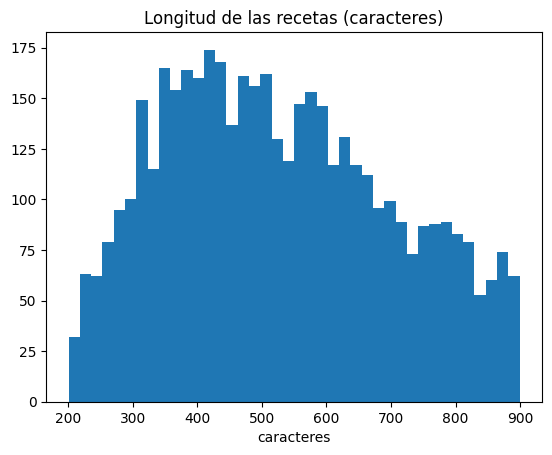

In [32]:
largos = [len(t) for t in ds_recetas["train"]["input"]]
plt.hist(largos, bins=40)
plt.title("Longitud de las recetas (caracteres)")
plt.xlabel("caracteres")
plt.show()

### 2.2 Decoder-only: SmolLM2-135M aprende a escribir recetas

**Causal Language Modeling**: el modelo aprende a predecir el siguiente token de cada receta. No hacen falta etiquetas: **el propio texto es la etiqueta** (desplazado una posición). El `DataCollatorForLanguageModeling(mlm=False)` se encarga de crear las etiquetas.

Primero vemos qué genera el modelo **antes** de entrenar:

In [33]:
nombre = "HuggingFaceTB/SmolLM2-135M"
tok_dec = AutoTokenizer.from_pretrained(nombre)
tok_dec.pad_token = tok_dec.eos_token          # SmolLM2 no tiene token de padding: usamos el de fin de texto
model_dec = AutoModelForCausalLM.from_pretrained(nombre).to(device)

titulos_prueba = ["Chocolate Banana Bread", "Spicy Chicken Tacos", "Grandma's Apple Pie"]


def probar_decoder(model):
    for t in titulos_prueba:
        prompt = f"{t}\n\nIngredients:\n"
        texto = generar(model, tok_dec, prompt, max_new_tokens=120, do_sample=True,
                        temperature=0.7, top_p=0.9, repetition_penalty=1.2)
        print(f"### {prompt}{texto}\n" + "-" * 60)


transformers.set_seed(SEED)
probar_decoder(model_dec)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

### Chocolate Banana Bread

Ingredients:
- 1 cup whole wheat flour (such as Self Care by St. Michael's)
- ½ tsp baking powder or salt
- 2 cups unsalted butter, melted and cooled slightly
- ¼ cup granulated sugar
- ⅓ cup rolled oats
- 4 eggs beaten with ¾ cup milk
- 3 tablespoons cocoa powder


------------------------------------------------------------
### Spicy Chicken Tacos

Ingredients:
- 1 package (20oz) whole chicken breast, cut into bite sized pieces
- 6 large eggs (about an ounce each), beaten together in a bowl or small pitcher
- 4 cups flour (all purpose mix for easy incorporation of ingredients; store bought is fine too!)
- ¾ cup water
- 3 tablespoons olive oil


------------------------------------------------------------
### Grandma's Apple Pie

Ingredients:
- 1 cup of sugar (you can use regular or brown)
- 3/4 teaspoon of baking powder
- 2 teaspoons of vanilla extract
- 8 oz. pie crust, cut into small pieces if desired; optional - store in an airtight container for up to 

Tokenizamos el dataset. Añadimos el token de fin de texto (`eos`) al final de cada receta para que el modelo aprenda **cuándo parar**.

In [34]:
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments

MAX_LEN_DEC = 256


def tokenizar_dec(batch):
    textos = [t + tok_dec.eos_token for t in batch["input"]]
    return tok_dec(textos, truncation=True, max_length=MAX_LEN_DEC)


ds_dec = ds_recetas.map(tokenizar_dec, batched=True, remove_columns=["input"])
collator_dec = DataCollatorForLanguageModeling(tokenizer=tok_dec, mlm=False)

# Veamos qué produce el collator: input_ids y labels (iguales; el modelo las desplaza internamente).
# Las posiciones de padding se marcan con -100 para que no cuenten en la loss.
ejemplo = collator_dec([ds_dec["train"][0], ds_dec["train"][1]])
print({k: v.shape for k, v in ejemplo.items()})
print(ejemplo["labels"][0][-10:])

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

{'input_ids': torch.Size([2, 206]), 'attention_mask': torch.Size([2, 206]), 'labels': torch.Size([2, 206])}
tensor([-100, -100, -100, -100, -100, -100, -100, -100, -100, -100])


In [35]:
args_dec = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/smollm2-recetas",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_dec = Trainer(
    model=model_dec,
    args=args_dec,
    train_dataset=ds_dec["train"],
    eval_dataset=ds_dec["test"],
    data_collator=collator_dec,
    processing_class=tok_dec,
)

# Perplejidad = exp(loss): "entre cuántos tokens duda el modelo de media". Cuanto más baja, mejor.
loss_antes = trainer_dec.evaluate()["eval_loss"]
print(f"ANTES  -> loss: {loss_antes:.3f} | perplejidad: {math.exp(loss_antes):.1f}")

{'eval_loss': '2.01', 'eval_model_preparation_time': '0.0058', 'eval_runtime': '16.04', 'eval_samples_per_second': '31.17', 'eval_steps_per_second': '3.928', 'epoch': 0}
ANTES  -> loss: 2.010 | perplejidad: 7.5


In [36]:
trainer_dec.train()

loss_despues = trainer_dec.evaluate()["eval_loss"]
print(f"ANTES   -> perplejidad: {math.exp(loss_antes):.1f}")
print(f"DESPUÉS -> perplejidad: {math.exp(loss_despues):.1f}")
if device == "cuda":
    print(f"Pico de VRAM: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

{'loss': '1.932', 'grad_norm': '2.797', 'learning_rate': '4.875e-05', 'epoch': '0.07105'}
{'loss': '1.847', 'grad_norm': '4.031', 'learning_rate': '4.857e-05', 'epoch': '0.1421'}
{'loss': '1.748', 'grad_norm': '3.375', 'learning_rate': '4.429e-05', 'epoch': '0.2131'}
{'loss': '1.765', 'grad_norm': '2.656', 'learning_rate': '3.769e-05', 'epoch': '0.2842'}
{'loss': '1.741', 'grad_norm': '2.906', 'learning_rate': '2.956e-05', 'epoch': '0.3552'}
{'loss': '1.745', 'grad_norm': '2.641', 'learning_rate': '2.087e-05', 'epoch': '0.4263'}
{'loss': '1.742', 'grad_norm': '2.562', 'learning_rate': '1.269e-05', 'epoch': '0.4973'}
{'loss': '1.72', 'grad_norm': '3.266', 'learning_rate': '5.99e-06', 'epoch': '0.5684'}
{'loss': '1.778', 'grad_norm': '3.75', 'learning_rate': '1.583e-06', 'epoch': '0.6394'}
{'loss': '1.746', 'grad_norm': '3.25', 'learning_rate': '9.519e-10', 'epoch': '0.7105'}
{'train_runtime': '308.4', 'train_samples_per_second': '10.38', 'train_steps_per_second': '1.297', 'train_loss': 

In [37]:
# ¿Ha mejorado el formato de las recetas?
transformers.set_seed(SEED)
probar_decoder(model_dec)

### Chocolate Banana Bread

Ingredients:
- 1/2 cup sugar
- 4 ounces chocolate chips, chopped fine
- 3 eggs beaten until blended and cooled to room temperature
- 6 tablespoons butter
- 7 cups flour (all purpose)
- 8 oz. milk or heavy cream (sifted with cinnamon for a creamy base; use unsweetened condensed milk if you prefer less liquid.)

Directions:
- Preheat oven to 500°F. Line baking sheet(ingredients are on the bottom of each dish). Mix together all ingredients except vanilla. Pour batter into
------------------------------------------------------------
### Spicy Chicken Tacos

Ingredients:
- 1 can (24 oz.) chicken broth, warmed to room temperature.
- 3 Tbsp. mayonnaise; or more for dipping sauce if desired.
- 8 garlic cloves, minced.
- 6 large zucchini, cut in half lengthwise and sliced thin.
- 5 cups chopped cilantro.
- 2 cans crushed tomatoes with their juice added as needed.
- 9 ounces shredded cheese such as cheddar, Monterey Jack, etc., finely grated.
- 7 eggs beaten until ver

In [38]:
# Guardar el modelo adaptado (luego se puede cargar con from_pretrained(ruta))
trainer_dec.save_model(f"{OUTPUT_DIR}/smollm2-recetas")
tok_dec.save_pretrained(f"{OUTPUT_DIR}/smollm2-recetas")

del model_dec, trainer_dec
liberar_memoria()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

VRAM ocupada: 0.88 GB


#### ¿Y si el modelo es más grande? LoRA

Con SmolLM2-135M podemos entrenar **todos** los pesos (*full fine-tuning*). Con modelos de miles de millones de parámetros no cabe en memoria, así que se usa **LoRA** (librería `peft`): se congelan los pesos originales y solo se entrenan unas matrices pequeñas añadidas. El resto del código (Trainer, collator...) es **idéntico**.

In [39]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [40]:
from peft import LoraConfig, get_peft_model

model_base = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M")
config_lora = LoraConfig(
    r=8,                                    # rango de las matrices LoRA
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],    # capas de atención en las que añadimos LoRA
    task_type="CAUSAL_LM",
)
model_lora = get_peft_model(model_base, config_lora)
model_lora.print_trainable_parameters()     # solo se entrena un porcentaje mínimo de los pesos

del model_base, model_lora
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

trainable params: 460,800 || all params: 134,975,808 || trainable%: 0.3414
VRAM ocupada: 0.88 GB


### 2.3 Encoder-decoder: Flan-T5-small, de título a receta

Ahora planteamos el problema como **seq2seq**: la **entrada** es el título y la **salida** son los ingredientes y los pasos. Así que hay que separar el título del resto de la receta.

> **Detalle importante:** el tokenizador de T5 **elimina los saltos de línea** (`\n`). Si entrenamos con el texto tal cual, el modelo nunca podrá generar el formato en líneas. Por eso convertimos cada receta a una sola línea, con `|` como separador, y la volvemos a "maquetar" al mostrarla.

In [41]:
tok_t5 = AutoTokenizer.from_pretrained("google/flan-t5-small")
print(tok_t5.tokenize("Ingredients:\n- 2 eggs"))  # ¡el \n desaparece!


def separar_receta(texto):
    # 'Título\n\nIngredients:\n- a\n...' -> ('Título', 'Ingredients: | - a | ...')
    titulo, _, cuerpo = texto.partition("\n")
    lineas = [l.strip() for l in cuerpo.strip().split("\n") if l.strip()]
    return titulo.strip(), " | ".join(lineas)


def maquetar(texto_una_linea):
    return texto_una_linea.replace(" | ", "\n")


titulo, cuerpo = separar_receta(ds_recetas["train"][0]["input"])
print("ENTRADA:", titulo)
print("SALIDA :", cuerpo[:200], "...")

['▁Ingredient', 's', ':', '▁', '-', '▁2', '▁eggs']
ENTRADA: Beef Tartar
SALIDA : Ingredients: | - 6 ounces beef tenderloin, fresh, very high quality | - 2 teaspoons Dijon mustard | - 1/2 teaspoon capers, chopped | - 1/2 teaspoon shallot, finely diced | - 1/2 teaspoon cornichon, fi ...


In [42]:
from transformers import DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments

nombre = "google/flan-t5-small"
tok_t5 = AutoTokenizer.from_pretrained(nombre)
model_t5 = AutoModelForSeq2SeqLM.from_pretrained(nombre).to(device)

PREFIJO = "Write a recipe for: "


def probar_t5(model):
    for t in titulos_prueba:
        texto = generar_seq2seq(model, tok_t5, PREFIJO + t, max_new_tokens=200,
                                num_beams=4, no_repeat_ngram_size=3)
        print(f"### {t}\n{maquetar(texto)}\n" + "-" * 60)


probar_t5(model_t5)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

### Chocolate Banana Bread
Chocolate Banana Bread
------------------------------------------------------------
### Spicy Chicken Tacos
Preheat oven to 375 degrees Fahrenheit (180 degrees Celsius) and grease a 9-inch baking pan with a butter knife. Place the chicken in a large skillet over medium heat. Add the chicken to the skillet and cook until the chicken is golden brown.
------------------------------------------------------------
### Grandma's Apple Pie
Grandma's Apple Pie
------------------------------------------------------------


In [43]:
MAX_LEN_ENTRADA, MAX_LEN_SALIDA = 32, 256


def tokenizar_t5(batch):
    titulos, cuerpos = zip(*[separar_receta(t) for t in batch["input"]])
    enc = tok_t5([PREFIJO + t for t in titulos], truncation=True, max_length=MAX_LEN_ENTRADA)
    enc["labels"] = tok_t5(text_target=list(cuerpos), truncation=True, max_length=MAX_LEN_SALIDA)["input_ids"]
    return enc


ds_t5 = ds_recetas.map(tokenizar_t5, batched=True, remove_columns=["input"])
collator_t5 = DataCollatorForSeq2Seq(tokenizer=tok_t5, model=model_t5)
ds_t5

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 4500
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 500
    })
})

In [44]:
args_t5 = Seq2SeqTrainingArguments(
    output_dir=f"{OUTPUT_DIR}/flan-t5-recetas",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-4,              # T5 suele necesitar un learning rate más alto que los decoders
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,                   # T5 es inestable en fp16 (da NaN): en la T4 entrenamos en fp32
    report_to="none",
    seed=SEED,
)

trainer_t5 = Seq2SeqTrainer(
    model=model_t5,
    args=args_t5,
    train_dataset=ds_t5["train"],
    eval_dataset=ds_t5["test"],
    data_collator=collator_t5,
    processing_class=tok_t5,
)

loss_antes = trainer_t5.evaluate()["eval_loss"]
trainer_t5.train()
loss_despues = trainer_t5.evaluate()["eval_loss"]
print(f"Loss de validación: {loss_antes:.3f} -> {loss_despues:.3f}")

{'eval_loss': '2.685', 'eval_model_preparation_time': '0.0049', 'eval_runtime': '9.609', 'eval_samples_per_second': '52.04', 'eval_steps_per_second': '6.557', 'epoch': 0}
{'loss': '2.565', 'grad_norm': '1.155', 'learning_rate': '0.0004875', 'epoch': '0.07105'}
{'loss': '2.19', 'grad_norm': '1.241', 'learning_rate': '0.0004857', 'epoch': '0.1421'}
{'loss': '2.039', 'grad_norm': '1.111', 'learning_rate': '0.0004429', 'epoch': '0.2131'}
{'loss': '2.074', 'grad_norm': '0.991', 'learning_rate': '0.0003769', 'epoch': '0.2842'}
{'loss': '2.012', 'grad_norm': '1.3', 'learning_rate': '0.0002956', 'epoch': '0.3552'}
{'loss': '1.984', 'grad_norm': '0.8949', 'learning_rate': '0.0002087', 'epoch': '0.4263'}
{'loss': '1.976', 'grad_norm': '0.8591', 'learning_rate': '0.0001269', 'epoch': '0.4973'}
{'loss': '1.94', 'grad_norm': '0.8667', 'learning_rate': '5.99e-05', 'epoch': '0.5684'}
{'loss': '1.984', 'grad_norm': '1.213', 'learning_rate': '1.583e-05', 'epoch': '0.6394'}
{'loss': '1.944', 'grad_norm'

In [45]:
probar_t5(model_t5)

### Chocolate Banana Bread
Ingredients:
- 1 1/2 c. sugar
-2 tsp. baking powder
-3 lb. chocolate chips
Directions: Preheat oven to 350°.
Using a mixer, beat together sugar, flour, baking powder, baking soda, and vanilla. Beat until smooth. Add bananas and mix well. Beat in remaining ingredients. Beat well. Pour into a greased 9 x 13-inch loaf pan. Bake at 350° for 30 to 40 minutes or until golden brown.
------------------------------------------------------------
### Spicy Chicken Tacos
Ingredients:
- 1 lb. chicken breasts, drained and sliced (about 1 1/2 c.)
-2 Tbsp. shredded cheddar cheese, sliced
Directions: (I use a sour cream, if you like, but don't use it, you can use it as a substitute for a cream of chicken soup). (If you want to add a pinch of salt, you may want to try it out.)
------------------------------------------------------------
### Grandma's Apple Pie
Ingredients:
- 1 lb. apple pie shell, drained and cut into squares (optional)
-2 c. butter, melted
-3 tsp. baking powd

In [46]:
trainer_t5.save_model(f"{OUTPUT_DIR}/flan-t5-recetas")
del model_t5, trainer_t5
liberar_memoria()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

VRAM ocupada: 1.19 GB


### 2.4 (Opcional) Encoder: DistilBERT aprende vocabulario de cocina

Un encoder también se puede adaptar al dominio: seguimos con su tarea de preentrenamiento (**Masked LM**) sobre las recetas. Esto se llama *Domain-Adaptive Pretraining* y es el paso previo habitual antes de entrenar un clasificador en un dominio especializado (médico, legal...).

Modelo: [`distilbert-base-uncased`](https://huggingface.co/distilbert/distilbert-base-uncased)

In [47]:
from transformers import AutoModelForMaskedLM

nombre = "distilbert-base-uncased"
tok_bert = AutoTokenizer.from_pretrained(nombre)
model_bert = AutoModelForMaskedLM.from_pretrained(nombre).to(device)

frases_mask = [
    "Preheat the [MASK] to 350 degrees.",
    "Mix the flour, sugar and [MASK] in a large bowl.",
    "Add 2 cups of shredded [MASK] cheese.",
]


def probar_bert(model):
    fm = pipeline("fill-mask", model=model, tokenizer=tok_bert, device=device)
    for f in frases_mask:
        print(f"{f:50s} -> {[p['token_str'] for p in fm(f, top_k=5)]}")


probar_bert(model_bert)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Preheat the [MASK] to 350 degrees.                 -> ['temperature', 'sun', 'furnace', 'heat', 'temperatures']
Mix the flour, sugar and [MASK] in a large bowl.   -> ['sugar', 'flour', 'milk', 'salt', 'water']
Add 2 cups of shredded [MASK] cheese.              -> ['goat', 'cream', 'cottage', 'milk', 'egg']


In [48]:
ds_bert = ds_recetas.map(lambda b: tok_bert(b["input"], truncation=True, max_length=256),
                         batched=True, remove_columns=["input"])

trainer_bert = Trainer(
    model=model_bert,
    args=TrainingArguments(
        output_dir=f"{OUTPUT_DIR}/distilbert-recetas",
        max_steps=max(10, MAX_STEPS // 2),
        per_device_train_batch_size=16,
        learning_rate=5e-5,
        logging_steps=max(1, MAX_STEPS // 10),
        save_strategy="no",
        bf16=USE_BF16,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
    ),
    train_dataset=ds_bert["train"],
    # mlm=True: tapa aleatoriamente el 15 % de los tokens y el modelo debe adivinarlos
    data_collator=DataCollatorForLanguageModeling(tokenizer=tok_bert, mlm=True, mlm_probability=0.15),
)
trainer_bert.train()
probar_bert(model_bert)

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

{'loss': '2.422', 'grad_norm': '7.54', 'learning_rate': '4.025e-05', 'epoch': '0.1418'}
{'loss': '1.968', 'grad_norm': '5.687', 'learning_rate': '3.025e-05', 'epoch': '0.2837'}
{'loss': '1.837', 'grad_norm': '6.739', 'learning_rate': '2.025e-05', 'epoch': '0.4255'}
{'loss': '1.696', 'grad_norm': '5.71', 'learning_rate': '1.025e-05', 'epoch': '0.5674'}
{'loss': '1.708', 'grad_norm': '6.058', 'learning_rate': '2.5e-07', 'epoch': '0.7092'}
{'train_runtime': '133.6', 'train_samples_per_second': '23.96', 'train_steps_per_second': '1.497', 'train_loss': '1.926', 'epoch': '0.7092'}
Preheat the [MASK] to 350 degrees.                 -> ['oven', 'temperature', 'heat', 'stove', 'heating']
Mix the flour, sugar and [MASK] in a large bowl.   -> ['water', 'flour', 'salt', 'milk', 'sugar']
Add 2 cups of shredded [MASK] cheese.              -> ['cottage', 'cream', 'swiss', 'italian', 'dutch']


In [49]:
del model_bert, trainer_bert
liberar_memoria()

VRAM ocupada: 1.19 GB


### Ejercicios — Sección 2

1. Inventa 5 títulos de recetas (algunos raros, como *"Chocolate Pizza with Tuna"*) y compáralos en el decoder y en el T5 adaptados. ¿Cuál respeta mejor el título? ¿Por qué crees que pasa?
2. Repite el entrenamiento del decoder con `MAX_STEPS` a la mitad y al doble. Apunta la perplejidad final y la calidad de las recetas. ¿Hay sobreajuste?
3. Cambia el `learning_rate` del decoder a `5e-4` y a `5e-6`. ¿Qué ocurre con la *loss*?
4. Carga el modelo guardado en `outputs/smollm2-recetas` con `AutoModelForCausalLM.from_pretrained(...)` y genera una receta con un prompt incompleto (por ejemplo, empezando ya los ingredientes).
5. **Reto**: cambia la tarea del T5 para que aprenda **ingredientes → título** (la tarea inversa). Solo tienes que modificar `tokenizar_t5`.
6. **Reto**: entrena el decoder con LoRA (apartado 2.2) en lugar de con *full fine-tuning*. Compara el tiempo, la memoria y el resultado.

In [50]:
# 1. Inventa 5 títulos de recetas (algunos raros, como "Chocolate Pizza with Tuna") y compáralos en el decoder y en el T5 adaptados. ¿Cuál respeta mejor el título? ¿Por qué crees que pasa?

titulos_raros = ["Chocolate Pizza with Tuna", "Strawberry Soup with Garlic", "Banana Sushi with Mustard",
                 "Coffee Spaghetti", "Pickle Ice Cream"]

# Cargamos los modelos que guardamos en 2.2 y 2.3
model_dec = AutoModelForCausalLM.from_pretrained(f"{OUTPUT_DIR}/smollm2-recetas").to(device)
model_t5 = AutoModelForSeq2SeqLM.from_pretrained(f"{OUTPUT_DIR}/flan-t5-recetas").to(device)

for t in titulos_raros:
    # Decoder: le damos el título y "Ingredients:" y continúa
    prompt = f"{t}\n\nIngredients:\n"
    print("### DECODER:", t)
    print(prompt + generar(model_dec, tok_dec, prompt, max_new_tokens=100, do_sample=True,
                           temperature=0.7, top_p=0.9, repetition_penalty=1.2))

    # T5: le damos el título con el prefijo y genera la receta entera
    print("### T5:", t)
    print(maquetar(generar_seq2seq(model_t5, tok_t5, PREFIJO + t, max_new_tokens=200,
                                   num_beams=4, no_repeat_ngram_size=3)))
    print("=" * 60)

del model_dec, model_t5
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

### DECODER: Chocolate Pizza with Tuna
Chocolate Pizza with Tuna

Ingredients:
- 1/2 cup flour (whole)
- 4 large eggs, room temperature
- 6 ounces cream cheese (unsalted), divided into two equal portions and set aside for later use.
- 3 tablespoons butter or margarine in small quantity; add to the egg mixture until it is well mixed but not thick enough to form a paste when lightly stirred up.
- 8 ounce can cannellini beans cooked through. Reserve half of this amount as you will
### T5: Chocolate Pizza with Tuna
Ingredients:
- 1 lb. ground beef, drained, sliced and sliced (about 1/4 c.)
-2 lg. sour cream
-3 lp. sliced onion
-6 oz. cream of celery soup
-1 pkg. nutmeg
-4 pt. salt
-5 psp. pepper
-8 pc. sugar
-10 pb. kosher salt
Directions: Preheat oven to 350°.
Using a large bowl, mix all ingredients together.
Direction:
In a small bowl, combine all ingredients.
In large mixing bowl, add salt and pepper. Mix well.
Bake at 350° for 30 minutes.
Makes 8 servings.
### DECODER: Strawberry Soup 

**Respuesta (ejercicio 1).** Ninguno de los dos respeta del todo los títulos raros, pero cada uno falla de forma distinta.

- **T5:** copia más las palabras del título. En 4 de las 5 recetas usa el ingrediente raro (*strawberries*, *banana*, *coffee* y *pickle*). Pero el texto sale confuso, con unidades inventadas ("lp.", "psp.") y frases repetidas. En *Chocolate Pizza with Tuna* ni usa chocolate ni atún.
- **Decoder:** escribe recetas más naturales y con buen formato, pero se aleja del título. En *Chocolate Pizza with Tuna* no hay chocolate ni atún, en *Coffee Spaghetti* no hay café y en *Pickle Ice Cream* no hay pepinillo. Solo usa el ingrediente raro en *Strawberry Soup with Garlic* (fresas, pero sin ajo) y en *Banana Sushi with Mustard* (plátano, pero sin mostaza).

**¿Por qué pasa?** El T5 lee el título con el encoder y lo consulta mientras escribe, así que lo copia más. Pero es pequeño y está poco entrenado, y por eso el texto sale peor. El decoder solo recibe el título como inicio del texto y ha aprendido cómo suelen ser las recetas, así que ante algo raro tira a la receta normal (harina, huevos, mantequilla). En resumen: el T5 respeta mejor las palabras del título y el decoder respeta mejor la forma de una receta.

In [51]:
#2. Repite el entrenamiento del decoder con `MAX_STEPS` a la mitad y al doble. Apunta la perplejidad final y la calidad de las recetas. ¿Hay sobreajuste?

MAX_STEPS_EJ = MAX_STEPS // 2
transformers.set_seed(SEED)
model_ej = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device)

args_ej = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/tmp-ejercicio",
    max_steps=MAX_STEPS_EJ,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS_EJ // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS_EJ // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_ej = Trainer(model=model_ej, args=args_ej, train_dataset=ds_dec["train"],
                     eval_dataset=ds_dec["test"], data_collator=collator_dec, processing_class=tok_dec)

loss_antes = trainer_ej.evaluate()["eval_loss"]
print(f"ANTES   -> perplejidad: {math.exp(loss_antes):.1f}")

trainer_ej.train()

loss_despues = trainer_ej.evaluate()["eval_loss"]
print(f"DESPUÉS ({MAX_STEPS_EJ} steps) -> perplejidad: {math.exp(loss_despues):.1f}")

transformers.set_seed(SEED)
probar_decoder(model_ej)

del model_ej, trainer_ej
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

{'eval_loss': '2.01', 'eval_model_preparation_time': '0.0054', 'eval_runtime': '17.01', 'eval_samples_per_second': '29.4', 'eval_steps_per_second': '3.704', 'epoch': 0}
ANTES   -> perplejidad: 7.5
{'loss': '1.979', 'grad_norm': '3.062', 'learning_rate': '4.75e-05', 'epoch': '0.03552'}
{'loss': '1.817', 'grad_norm': '2.766', 'learning_rate': '4.864e-05', 'epoch': '0.07105'}
{'loss': '1.842', 'grad_norm': '3.375', 'learning_rate': '4.443e-05', 'epoch': '0.1066'}
{'loss': '1.816', 'grad_norm': '4.062', 'learning_rate': '3.788e-05', 'epoch': '0.1421'}
{'loss': '1.752', 'grad_norm': '2.75', 'learning_rate': '2.977e-05', 'epoch': '0.1776'}
{'loss': '1.751', 'grad_norm': '3.375', 'learning_rate': '2.109e-05', 'epoch': '0.2131'}
{'loss': '1.802', 'grad_norm': '3.281', 'learning_rate': '1.288e-05', 'epoch': '0.2487'}
{'loss': '1.756', 'grad_norm': '2.688', 'learning_rate': '6.132e-06', 'epoch': '0.2842'}
{'loss': '1.765', 'grad_norm': '3.156', 'learning_rate': '1.66e-06', 'epoch': '0.3197'}
{'l

In [52]:
#2. Repite el entrenamiento del decoder con `MAX_STEPS` a la mitad y al doble. Apunta la perplejidad final y la calidad de las recetas. ¿Hay sobreajuste?

MAX_STEPS_EJ = MAX_STEPS

transformers.set_seed(SEED)
model_ej = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device)

args_ej = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/tmp-ejercicio",
    max_steps=MAX_STEPS_EJ,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS_EJ // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS_EJ // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_ej = Trainer(model=model_ej, args=args_ej, train_dataset=ds_dec["train"],
                     eval_dataset=ds_dec["test"], data_collator=collator_dec, processing_class=tok_dec)

loss_antes = trainer_ej.evaluate()["eval_loss"]
print(f"ANTES   -> perplejidad: {math.exp(loss_antes):.1f}")

trainer_ej.train()

loss_despues = trainer_ej.evaluate()["eval_loss"]
print(f"DESPUÉS ({MAX_STEPS_EJ} steps) -> perplejidad: {math.exp(loss_despues):.1f}")

transformers.set_seed(SEED)
probar_decoder(model_ej)

del model_ej, trainer_ej
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

{'eval_loss': '2.01', 'eval_model_preparation_time': '0.0054', 'eval_runtime': '16.73', 'eval_samples_per_second': '29.88', 'eval_steps_per_second': '3.765', 'epoch': 0}
ANTES   -> perplejidad: 7.5
{'loss': '1.932', 'grad_norm': '2.797', 'learning_rate': '4.875e-05', 'epoch': '0.07105'}
{'loss': '1.847', 'grad_norm': '4.031', 'learning_rate': '4.857e-05', 'epoch': '0.1421'}
{'loss': '1.748', 'grad_norm': '3.375', 'learning_rate': '4.429e-05', 'epoch': '0.2131'}
{'loss': '1.765', 'grad_norm': '2.656', 'learning_rate': '3.769e-05', 'epoch': '0.2842'}
{'loss': '1.741', 'grad_norm': '2.906', 'learning_rate': '2.956e-05', 'epoch': '0.3552'}
{'loss': '1.745', 'grad_norm': '2.641', 'learning_rate': '2.087e-05', 'epoch': '0.4263'}
{'loss': '1.742', 'grad_norm': '2.562', 'learning_rate': '1.269e-05', 'epoch': '0.4973'}
{'loss': '1.72', 'grad_norm': '3.266', 'learning_rate': '5.99e-06', 'epoch': '0.5684'}
{'loss': '1.778', 'grad_norm': '3.75', 'learning_rate': '1.583e-06', 'epoch': '0.6394'}
{'l

In [53]:
#2. Repite el entrenamiento del decoder con `MAX_STEPS` a la mitad y al doble. Apunta la perplejidad final y la calidad de las recetas. ¿Hay sobreajuste?

MAX_STEPS_EJ = MAX_STEPS * 2

transformers.set_seed(SEED)
model_ej = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device)

args_ej = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/tmp-ejercicio",
    max_steps=MAX_STEPS_EJ,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS_EJ // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS_EJ // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_ej = Trainer(model=model_ej, args=args_ej, train_dataset=ds_dec["train"],
                     eval_dataset=ds_dec["test"], data_collator=collator_dec, processing_class=tok_dec)

loss_antes = trainer_ej.evaluate()["eval_loss"]
print(f"ANTES   -> perplejidad: {math.exp(loss_antes):.1f}")

trainer_ej.train()

loss_despues = trainer_ej.evaluate()["eval_loss"]
print(f"DESPUÉS ({MAX_STEPS_EJ} steps) -> perplejidad: {math.exp(loss_despues):.1f}")

transformers.set_seed(SEED)
probar_decoder(model_ej)

del model_ej, trainer_ej
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

{'eval_loss': '2.01', 'eval_model_preparation_time': '0.0075', 'eval_runtime': '16.77', 'eval_samples_per_second': '29.82', 'eval_steps_per_second': '3.758', 'epoch': 0}
ANTES   -> perplejidad: 7.5
{'loss': '1.934', 'grad_norm': '4.188', 'learning_rate': '4.938e-05', 'epoch': '0.1421'}
{'loss': '1.773', 'grad_norm': '2.672', 'learning_rate': '4.853e-05', 'epoch': '0.2842'}
{'loss': '1.74', 'grad_norm': '2.641', 'learning_rate': '4.422e-05', 'epoch': '0.4263'}
{'loss': '1.718', 'grad_norm': '3.172', 'learning_rate': '3.759e-05', 'epoch': '0.5684'}
{'loss': '1.741', 'grad_norm': '2.953', 'learning_rate': '2.945e-05', 'epoch': '0.7105'}
{'loss': '1.733', 'grad_norm': '3', 'learning_rate': '2.077e-05', 'epoch': '0.8526'}
{'loss': '1.712', 'grad_norm': '3.938', 'learning_rate': '1.259e-05', 'epoch': '0.9947'}
{'loss': '1.712', 'grad_norm': '2.375', 'learning_rate': '5.919e-06', 'epoch': '1.137'}
{'loss': '1.711', 'grad_norm': '2.75', 'learning_rate': '1.545e-06', 'epoch': '1.279'}
{'loss': 

**Respuesta (ejercicio 2).**

| Pasos | Perplejidad (antes → después) | Loss de entrenamiento | Loss de validación |
|---|---|---|---|
| 200 (la mitad) | 7,5 → **5,9** | 1,80 | 1,77 |
| 400 (normal) | 7,5 → **5,7** | 1,78 | 1,74 |
| 800 (el doble) | 7,5 → **5,5** | 1,75 | 1,71 |

- **Calidad de las recetas:** en los tres casos el modelo ya respeta el formato (título, *Ingredients*, *Directions*), pero el contenido sigue teniendo cosas raras, como cantidades absurdas o ingredientes que no pegan (con 800 pasos sale beicon en un *Chocolate Banana Bread*). No veo una mejora clara a simple vista, solo en el número.
- **¿Hay sobreajuste?** No. La perplejidad sigue bajando al doblar los pasos (5,9 → 5,7 → 5,5) y la loss de entrenamiento y la de validación son casi iguales (1,75 y 1,71 con 800 pasos). Además, con 800 pasos solo ha dado 1,4 vueltas al dataset. Eso sí, la mejora es pequeña (unos 0,2 cada vez) aunque el tiempo se duplica.

In [54]:
# 3. Cambia el `learning_rate` del decoder a `5e-4` y a `5e-6`. ¿Qué ocurre con la *loss*?

LR_EJ = 5e-4

transformers.set_seed(SEED)
model_ej = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device)

args_ej = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/tmp-ejercicio",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LR_EJ,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_ej = Trainer(model=model_ej, args=args_ej, train_dataset=ds_dec["train"],
                     eval_dataset=ds_dec["test"], data_collator=collator_dec, processing_class=tok_dec)

trainer_ej.train()

loss = trainer_ej.evaluate()["eval_loss"]
print(f"learning_rate={LR_EJ} -> perplejidad: {math.exp(loss):.1f}")

del model_ej, trainer_ej
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

{'loss': '1.806', 'grad_norm': '1.875', 'learning_rate': '0.0004875', 'epoch': '0.07105'}
{'loss': '1.798', 'grad_norm': '2.25', 'learning_rate': '0.0004857', 'epoch': '0.1421'}
{'loss': '1.703', 'grad_norm': '1.945', 'learning_rate': '0.0004429', 'epoch': '0.2131'}
{'loss': '1.7', 'grad_norm': '1.539', 'learning_rate': '0.0003769', 'epoch': '0.2842'}
{'loss': '1.65', 'grad_norm': '1.547', 'learning_rate': '0.0002956', 'epoch': '0.3552'}
{'loss': '1.624', 'grad_norm': '1.414', 'learning_rate': '0.0002087', 'epoch': '0.4263'}
{'loss': '1.608', 'grad_norm': '1.5', 'learning_rate': '0.0001269', 'epoch': '0.4973'}
{'loss': '1.572', 'grad_norm': '1.438', 'learning_rate': '5.99e-05', 'epoch': '0.5684'}
{'loss': '1.628', 'grad_norm': '2.016', 'learning_rate': '1.583e-05', 'epoch': '0.6394'}
{'loss': '1.604', 'grad_norm': '1.68', 'learning_rate': '9.519e-09', 'epoch': '0.7105'}
{'train_runtime': '308.4', 'train_samples_per_second': '10.38', 'train_steps_per_second': '1.297', 'train_loss': '1.6

In [55]:
# 3. Cambia el `learning_rate` del decoder a `5e-4` y a `5e-6`. ¿Qué ocurre con la *loss*?

LR_EJ = 5e-6

transformers.set_seed(SEED)
model_ej = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device)

args_ej = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/tmp-ejercicio",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LR_EJ,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_ej = Trainer(model=model_ej, args=args_ej, train_dataset=ds_dec["train"],
                     eval_dataset=ds_dec["test"], data_collator=collator_dec, processing_class=tok_dec)

trainer_ej.train()

loss = trainer_ej.evaluate()["eval_loss"]
print(f"learning_rate={LR_EJ} -> perplejidad: {math.exp(loss):.1f}")

del model_ej, trainer_ej
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

{'loss': '1.979', 'grad_norm': '4.281', 'learning_rate': '4.875e-06', 'epoch': '0.07105'}
{'loss': '2.025', 'grad_norm': '5.531', 'learning_rate': '4.857e-06', 'epoch': '0.1421'}
{'loss': '1.968', 'grad_norm': '5.031', 'learning_rate': '4.429e-06', 'epoch': '0.2131'}
{'loss': '1.979', 'grad_norm': '3.797', 'learning_rate': '3.769e-06', 'epoch': '0.2842'}
{'loss': '1.958', 'grad_norm': '4.094', 'learning_rate': '2.956e-06', 'epoch': '0.3552'}
{'loss': '1.975', 'grad_norm': '3.922', 'learning_rate': '2.087e-06', 'epoch': '0.4263'}
{'loss': '1.973', 'grad_norm': '3.828', 'learning_rate': '1.269e-06', 'epoch': '0.4973'}
{'loss': '1.948', 'grad_norm': '4.188', 'learning_rate': '5.99e-07', 'epoch': '0.5684'}
{'loss': '2.003', 'grad_norm': '5.25', 'learning_rate': '1.583e-07', 'epoch': '0.6394'}
{'loss': '1.97', 'grad_norm': '3.859', 'learning_rate': '9.519e-11', 'epoch': '0.7105'}
{'train_runtime': '310.7', 'train_samples_per_second': '10.3', 'train_steps_per_second': '1.288', 'train_loss': 

**Respuesta (ejercicio 3).** Con el learning rate de siempre (`5e-5`) la perplejidad final era 5,7.

- **`5e-4`:** la loss baja más rápido y más abajo (de 1,81 a unos 1,60) y la perplejidad final es **4,8**, la mejor de todas. No se descontrola.
- **`5e-6`:** la loss casi no se mueve (se queda en torno a 1,97) y la perplejidad solo baja de 7,5 a **7,2**. Es decir, el modelo apenas aprende.

Con tan pocos pasos, un learning rate demasiado bajo deja al modelo casi igual que al principio, y uno más alto aprende mucho más rápido.

In [56]:
# 4. Carga el modelo guardado en `outputs/smollm2-recetas` con `AutoModelForCausalLM.from_pretrained(...)` y genera una receta con un prompt incompleto (por ejemplo, empezando ya los ingredientes).

model_guardado = AutoModelForCausalLM.from_pretrained(f"{OUTPUT_DIR}/smollm2-recetas").to(device)

prompt = "Lemon Garlic Shrimp\n\nIngredients:\n- 1 lb shrimp\n- 3 cloves garlic\n"

print(prompt + generar(model_guardado, tok_dec, prompt, max_new_tokens=150, do_sample=True,
                       temperature=0.7, top_p=0.9, repetition_penalty=1.2))

del model_guardado
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Lemon Garlic Shrimp

Ingredients:
- 1 lb shrimp
- 3 cloves garlic
- 2 tbsp olive oil, divided
- 8 oz. shrimps
- 4 lbs beef or chicken breast (or other large meat) cut into bite sized pieces
- salt and pepper to taste


  1. Place all ingredients in a small bowl, cover with plastic wrap, shake well until the flavors are combined; then put back together on serving platter.

  2. Serve immediately upon adding it to your favorite side dishes!

VRAM ocupada: 1.19 GB


**Respuesta (ejercicio 4).** He cargado el modelo guardado con `from_pretrained` y le he dado una receta ya empezada (*Lemon Garlic Shrimp* con gambas y ajo). El modelo sigue la lista de ingredientes (aceite de oliva, sal y pimienta…) y después pasa solo a los pasos, con el mismo formato que las recetas del entrenamiento. Se nota que ha aprendido la estructura, aunque el contenido no es muy coherente: añade "4 lbs beef or chicken breast" en una receta de gambas y en los pasos no usa el limón.

In [57]:
# 5. **Reto**: cambia la tarea del T5 para que aprenda **ingredientes → título** (la tarea inversa). Solo tienes que modificar `tokenizar_t5`.

PREFIJO_INV = "Write a title for a recipe with these ingredients: "

def tokenizar_t5_inverso(batch):
    titulos, cuerpos = zip(*[separar_receta(t) for t in batch["input"]])
    ingredientes = [c.split("Directions:")[0] for c in cuerpos]
    enc = tok_t5([PREFIJO_INV + i for i in ingredientes], truncation=True, max_length=256)
    enc["labels"] = tok_t5(text_target=list(titulos), truncation=True, max_length=32)["input_ids"]
    return enc

ds_t5_inv = ds_recetas.map(tokenizar_t5_inverso, batched=True, remove_columns=["input"])

model_t5_inv = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small").to(device)
collator_inv = DataCollatorForSeq2Seq(tokenizer=tok_t5, model=model_t5_inv)

args_inv = Seq2SeqTrainingArguments(
    output_dir=f"{OUTPUT_DIR}/flan-t5-titulos",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-4,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    report_to="none",
    seed=SEED,
)

trainer_inv = Seq2SeqTrainer(model=model_t5_inv, args=args_inv, train_dataset=ds_t5_inv["train"],
                             eval_dataset=ds_t5_inv["test"], data_collator=collator_inv,
                             processing_class=tok_t5)
trainer_inv.train()

prueba = "Ingredients: | - 2 cups flour | - 1 cup sugar | - 3 eggs | - 1 cup chocolate chips"
print(generar_seq2seq(model_t5_inv, tok_t5, PREFIJO_INV + prueba, max_new_tokens=20, num_beams=4))

del model_t5_inv, trainer_inv
liberar_memoria()

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

{'loss': '3.602', 'grad_norm': '5.651', 'learning_rate': '0.0004875', 'epoch': '0.07105'}
{'loss': '3.409', 'grad_norm': '5.015', 'learning_rate': '0.0004857', 'epoch': '0.1421'}
{'loss': '3.183', 'grad_norm': '5.356', 'learning_rate': '0.0004429', 'epoch': '0.2131'}
{'loss': '3.166', 'grad_norm': '6.299', 'learning_rate': '0.0003769', 'epoch': '0.2842'}
{'loss': '2.936', 'grad_norm': '5.098', 'learning_rate': '0.0002956', 'epoch': '0.3552'}
{'loss': '2.956', 'grad_norm': '6.534', 'learning_rate': '0.0002087', 'epoch': '0.4263'}
{'loss': '2.972', 'grad_norm': '4.972', 'learning_rate': '0.0001269', 'epoch': '0.4973'}
{'loss': '2.896', 'grad_norm': '5.282', 'learning_rate': '5.99e-05', 'epoch': '0.5684'}
{'loss': '3.086', 'grad_norm': '6.462', 'learning_rate': '1.583e-05', 'epoch': '0.6394'}
{'loss': '3.001', 'grad_norm': '3.744', 'learning_rate': '9.519e-09', 'epoch': '0.7105'}
{'train_runtime': '66.46', 'train_samples_per_second': '48.15', 'train_steps_per_second': '6.019', 'train_loss

**Respuesta (ejercicio 5).** Para la tarea inversa solo he cambiado la función de tokenización (`tokenizar_t5_inverso`): ahora la entrada es un prefijo (`Write a title for a recipe with these ingredients:`) más los ingredientes, y lo que el modelo tiene que generar es el título. Tras el entrenamiento la loss baja de 3,60 a unos 3,0. Con ingredientes de galletas (harina, azúcar, huevos y chispas de chocolate) genera **"Creamy Chocolate Chip Cookies"**, que es un título que tiene sentido. Solo lo he probado con un ejemplo, pero la tarea inversa funciona.

In [58]:
# 6. **Reto**: entrena el decoder con LoRA (apartado 2.2) en lugar de con *full fine-tuning*. Compara el tiempo, la memoria y el resultado.

import time
from peft import LoraConfig, get_peft_model

if device == "cuda":
    torch.cuda.reset_peak_memory_stats()

transformers.set_seed(SEED)
base = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device)
config_lora = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05,
                         target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
model_ej = get_peft_model(base, config_lora)
model_ej.print_trainable_parameters()

args_ej = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/tmp-lora",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_ej = Trainer(model=model_ej, args=args_ej, train_dataset=ds_dec["train"],
                     eval_dataset=ds_dec["test"], data_collator=collator_dec, processing_class=tok_dec)

inicio = time.time()
trainer_ej.train()
print(f"Tiempo de entrenamiento: {time.time() - inicio:.0f} segundos")
if device == "cuda":
    print(f"Pico de VRAM: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

loss = trainer_ej.evaluate()["eval_loss"]
print(f"LoRA -> perplejidad: {math.exp(loss):.1f}")

transformers.set_seed(SEED)
probar_decoder(model_ej)

del base, model_ej, trainer_ej
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

trainable params: 460,800 || all params: 134,975,808 || trainable%: 0.3414
{'loss': '1.946', 'grad_norm': '0.1772', 'learning_rate': '0.000195', 'epoch': '0.07105'}
{'loss': '1.891', 'grad_norm': '0.2783', 'learning_rate': '0.0001943', 'epoch': '0.1421'}
{'loss': '1.77', 'grad_norm': '0.2884', 'learning_rate': '0.0001772', 'epoch': '0.2131'}
{'loss': '1.778', 'grad_norm': '0.2555', 'learning_rate': '0.0001508', 'epoch': '0.2842'}
{'loss': '1.752', 'grad_norm': '0.2833', 'learning_rate': '0.0001182', 'epoch': '0.3552'}
{'loss': '1.752', 'grad_norm': '0.2839', 'learning_rate': '8.35e-05', 'epoch': '0.4263'}
{'loss': '1.749', 'grad_norm': '0.2927', 'learning_rate': '5.076e-05', 'epoch': '0.4973'}
{'loss': '1.726', 'grad_norm': '0.2835', 'learning_rate': '2.396e-05', 'epoch': '0.5684'}
{'loss': '1.783', 'grad_norm': '0.3714', 'learning_rate': '6.333e-06', 'epoch': '0.6394'}
{'loss': '1.751', 'grad_norm': '0.3284', 'learning_rate': '3.808e-09', 'epoch': '0.7105'}
{'train_runtime': '247.2', 

In [130]:
# Ejercicio 6 (medición de apoyo): MISMO entrenamiento con full fine-tuning, midiendo tiempo y pico de VRAM
# para compararlo con LoRA.
import time

if device == "cuda":
    torch.cuda.reset_peak_memory_stats()

transformers.set_seed(SEED)
model_full = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M").to(device)

args_full = TrainingArguments(
    output_dir=f"{OUTPUT_DIR}/tmp-full",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    weight_decay=0.01,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    fp16=USE_FP16,
    report_to="none",
    seed=SEED,
)

trainer_full = Trainer(model=model_full, args=args_full, train_dataset=ds_dec["train"],
                       eval_dataset=ds_dec["test"], data_collator=collator_dec, processing_class=tok_dec)

inicio = time.time()
trainer_full.train()
print(f"Tiempo de entrenamiento: {time.time() - inicio:.0f} segundos")
if device == "cuda":
    print(f"Pico de VRAM: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
print(f"Full fine-tuning -> perplejidad: {math.exp(trainer_full.evaluate()['eval_loss']):.1f}")

del model_full, trainer_full
liberar_memoria()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

{'loss': '1.932', 'grad_norm': '2.797', 'learning_rate': '4.875e-05', 'epoch': '0.07105'}
{'loss': '1.847', 'grad_norm': '4.031', 'learning_rate': '4.857e-05', 'epoch': '0.1421'}
{'loss': '1.748', 'grad_norm': '3.375', 'learning_rate': '4.429e-05', 'epoch': '0.2131'}
{'loss': '1.765', 'grad_norm': '2.656', 'learning_rate': '3.769e-05', 'epoch': '0.2842'}
{'loss': '1.741', 'grad_norm': '2.906', 'learning_rate': '2.956e-05', 'epoch': '0.3552'}
{'loss': '1.745', 'grad_norm': '2.641', 'learning_rate': '2.087e-05', 'epoch': '0.4263'}
{'loss': '1.742', 'grad_norm': '2.562', 'learning_rate': '1.269e-05', 'epoch': '0.4973'}
{'loss': '1.72', 'grad_norm': '3.266', 'learning_rate': '5.99e-06', 'epoch': '0.5684'}
{'loss': '1.778', 'grad_norm': '3.75', 'learning_rate': '1.583e-06', 'epoch': '0.6394'}
{'loss': '1.746', 'grad_norm': '3.25', 'learning_rate': '9.519e-10', 'epoch': '0.7105'}
{'train_runtime': '311.6', 'train_samples_per_second': '10.27', 'train_steps_per_second': '1.284', 'train_loss': 

**Respuesta (ejercicio 6).**

| | Full fine-tuning | LoRA |
|---|---|---|
| Parámetros que se entrenan | 135 M (todos) | 0,46 M (**0,34 %**) |
| Tiempo (400 pasos) | 315 s | **248 s** |
| Pico de VRAM | 7,04 GB | **5,09 GB** |
| Perplejidad final | 5,7 | **5,7** |

- **Tiempo:** LoRA tarda menos (248 s frente a 315 s, un 21 % menos).
- **Memoria:** LoRA usa menos (5,09 GB frente a 7,04 GB, un 28 % menos), porque solo guarda gradientes y datos del optimizador de los pocos parámetros que entrena.
- **Resultado:** la perplejidad es la misma (5,7) y las recetas tienen el mismo formato, aunque LoRA solo entrena el 0,34 % de los parámetros.

Con un modelo pequeño como este la diferencia no es muy grande, pero con modelos más grandes el ahorro de memoria sería mucho más importante.

---
## 3. Parámetros de generación y *chat templates*

En esta sección trabajamos solo con un **decoder-only** ajustado para chat: [`Qwen/Qwen2.5-0.5B-Instruct`](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct).

### 3.1 ¿Cómo elige el modelo el siguiente token?

En cada paso, el modelo devuelve un **logit** por cada token del vocabulario (más de 150 000 en Qwen). Hay varias estrategias para elegir:

| Parámetro | Qué hace | Efecto |
|---|---|---|
| `do_sample=False` (*greedy*) | Elige siempre el token más probable | Determinista, pero tiende a repetirse |
| `temperature` | Divide los logits por T antes del softmax | T < 1: más conservador · T > 1: más creativo/caótico |
| `top_k` | Solo considera los k tokens más probables | Elimina la "cola" de tokens absurdos |
| `top_p` (*nucleus*) | Solo considera los tokens más probables hasta sumar una probabilidad p | Como top_k, pero adaptativo |
| `repetition_penalty` | Penaliza los tokens que ya han aparecido | Menos bucles |
| `num_beams` | *Beam search*: explora varias secuencias a la vez | Mejores frases "probables", menos variedad |
| `max_new_tokens` | Longitud máxima de la respuesta | – |

In [59]:
nombre = "Qwen/Qwen2.5-0.5B-Instruct"
tok_chat = AutoTokenizer.from_pretrained(nombre)
model_chat = AutoModelForCausalLM.from_pretrained(nombre, dtype=DTYPE_INFERENCIA).to(device)
print(contar_parametros(model_chat))
print("Tamaño del vocabulario:", len(tok_chat))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

494M parámetros
Tamaño del vocabulario: 151665


Visualicemos la distribución del **siguiente token** y cómo la modifican la temperatura, top-k y top-p:

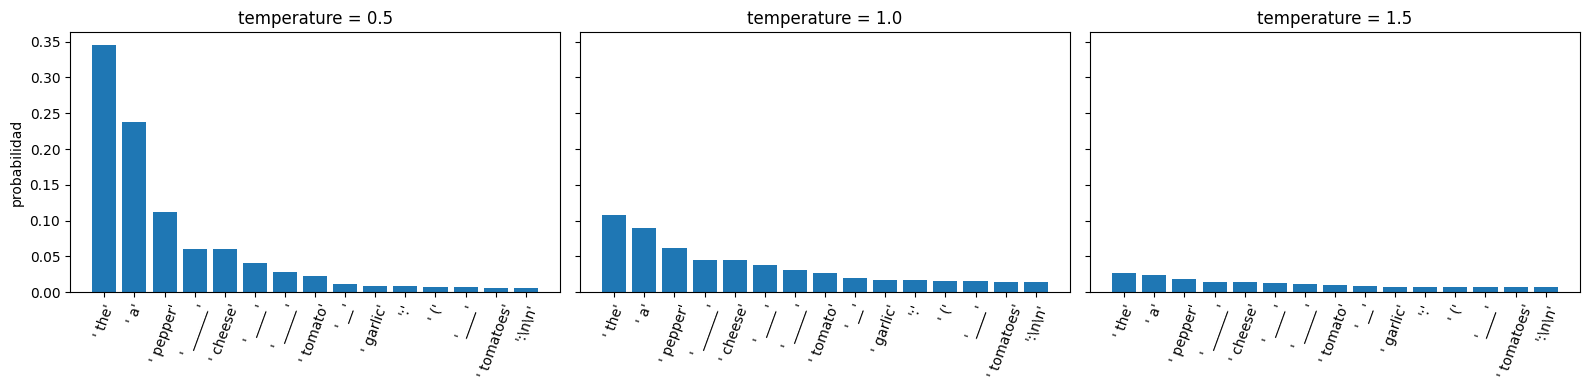

In [60]:
prompt = "My favourite ingredient for a pizza is"
enc = tok_chat(prompt, return_tensors="pt").to(device)
with torch.no_grad():
    logits = model_chat(**enc).logits[0, -1].float()

N = 15
top_ids = logits.topk(N).indices
etiquetas = [repr(tok_chat.decode(i)) for i in top_ids]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 1.5]):
    probs = (logits / T).softmax(-1)[top_ids].cpu()
    ax.bar(range(N), probs)
    ax.set_xticks(range(N), etiquetas, rotation=70)
    ax.set_title(f"temperature = {T}")
axes[0].set_ylabel("probabilidad")
plt.tight_layout()
plt.show()

In [61]:
# ¿Qué tokens "sobreviven" a top-k y top-p (con T=1)?
probs = logits.softmax(-1)
ordenadas, indices = probs.sort(descending=True)
acumulada = ordenadas.cumsum(-1)

k, p = 5, 0.9
n_top_p = int((acumulada < p).sum()) + 1
print(f"top_k={k}: se queda con {k} tokens -> {[tok_chat.decode(i) for i in indices[:k]]}")
print(f"top_p={p}: se queda con {n_top_p} tokens (los que suman el {p:.0%} de la probabilidad)")
print("Probabilidad acumulada de los 10 primeros:", [round(x, 3) for x in acumulada[:10].tolist()])

top_k=5: se queda con 5 tokens -> [' the', ' a', ' pepper', ' cheese', ' ______']
top_p=0.9: se queda con 267 tokens (los que suman el 90% de la probabilidad)
Probabilidad acumulada de los 10 primeros: [0.108, 0.198, 0.26, 0.305, 0.35, 0.388, 0.419, 0.446, 0.466, 0.484]


### 3.2 Probando los parámetros

Para no mezclar conceptos, de momento ignora la función `chat`: la explicaremos en el apartado 3.3. Simplemente le pasamos una lista de mensajes y parámetros de generación.

In [62]:
@torch.no_grad()
def chat(messages, model=None, tok=None, **gen_kwargs):
    model, tok = model or model_chat, tok or tok_chat
    inputs = tok.apply_chat_template(messages, add_generation_prompt=True,
                                     return_tensors="pt", return_dict=True).to(model.device)
    gen_kwargs.setdefault("max_new_tokens", 80)
    out = model.generate(**inputs, **gen_kwargs)
    return tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


pregunta = [{"role": "user", "content": "Write a one-sentence slogan for a bakery."}]

In [63]:
print("GREEDY (siempre igual):")
for _ in range(2):
    print("  ", chat(pregunta, do_sample=False))

for T in [0.2, 0.8, 1.5]:
    print(f"\ntemperature={T}:")
    for _ in range(3):
        print("  ", chat(pregunta, do_sample=True, temperature=T, top_k=0, top_p=1.0))

GREEDY (siempre igual):
   "Fresh from the oven, every bite is a delight."
   "Fresh from the oven, every bite is a delight."

temperature=0.2:
   "Fresh from the Garden, Sweet as a Dream - Enjoy Our Baked Delights!"
   "Fresh, delicious, and made with love - every bite is a moment of joy."
   "Delight in Every Bite, Sweetness of Life."

temperature=0.8:
   Let your love shine in the sweet moments of baking and delighting others with delicious bread and pies!
   "To taste the perfect blend of warmth and deliciousness in every bite!"
   "Fresh Baked Moments—Delightful Savoring Every Taste."

temperature=1.5:
   "A_surface o_successy flourishing supplier building tie Beneath purr-time wholesome recipie arguably pause," encourages option for making your cakes淄博🌸 rather than feet shamefully Giovanni Fleming Fake Suppliers Nike Collection Inاري深层 antagonist motto advocating righteousness beyond the veneerincible online right.const cocoerto burning Heyogl Various fifitta advancements GlossCh

In [64]:
configs = {
    "top_k=1 (equivale a greedy)": dict(do_sample=True, top_k=1),
    "top_k=50": dict(do_sample=True, top_k=50, top_p=1.0, temperature=1.2),
    "top_p=0.5": dict(do_sample=True, top_p=0.5, top_k=0, temperature=1.2),
    "top_p=0.95": dict(do_sample=True, top_p=0.95, top_k=0, temperature=1.2),
    "beam search (4 beams)": dict(do_sample=False, num_beams=4),
}
for nombre_cfg, cfg in configs.items():
    print(f"{nombre_cfg:28s} -> {chat(pregunta, **cfg)}")

top_k=1 (equivale a greedy)  -> "Fresh from the oven, every bite is a delight."
top_k=50                     -> "Cooking dreams in every bite: The Taste of Life at BreadKraft!" "Welcome to our cozy, delicious bakery; explore flavors that transcend culinary boundaries and delight all senses! Try some treats today."
top_p=0.5                    -> "Elevate your culinary experience with us – the perfect spot to explore and indulge in delightful bakery treats!"
top_p=0.95                   -> 博睿狂欢，甜品之都。随着节日和激情的不断增长，赛鸟星宇意在为观众带来非凡视觉与甜蜜体验的奇特邂逅——你的味蕾时刻会展出现实中的极致享受！我宣布：博瑞套餐，甜探背后。
beam search (4 beams)        -> "Crafted with love, every bite is a story of joy and nostalgia."


In [65]:
# repetition_penalty: probamos con una tarea que invita a repetirse
lista = [{"role": "user", "content": "List 15 ingredients for a salad, one per line."}]
for rp in [1.0, 1.3]:
    print(f"--- repetition_penalty={rp}")
    print(chat(lista, do_sample=False, repetition_penalty=rp, max_new_tokens=120), "\n")

--- repetition_penalty=1.0
1. Cherry tomatoes
2. Red onion
3. Cucumber
4. Spinach
5. Feta cheese
6. Kalamata olives
7. Red bell pepper
8. Red onion
9. Red radish
10. Red radish
11. Red onion
12. Red bell pepper
13. Red onion
14. Red bell pepper
15. Red onion 

--- repetition_penalty=1.3
Here is the list of fifteen common and nutritious ingredients that can be used in salads:

- **Broccoli** - A cruciferous vegetable with high nutritional value.
  
- **Spinach** - Rich source of vitamins K (antioxidants), C, E, folate, iron.

- **Bell Peppers** - Bright red or yellow peppers packed with vitamin C and other antioxidants.

- **Carrots** - Carotenoids like beta-carotene provide health benefits including anti-inflammatory properties.

- **Cucumbers** - High water content makes them refreshing but also rich in minerals 



#### `GenerationConfig`

Cada modelo trae una configuración de generación **por defecto** (decidida por sus autores), que se aplica cuando no indicamos nada. También podemos crear la nuestra y reutilizarla:

In [66]:
from transformers import GenerationConfig

print("Configuración por defecto de Qwen:\n", model_chat.generation_config)

creativa = GenerationConfig(do_sample=True, temperature=1.1, top_p=0.95, top_k=50,
                            max_new_tokens=60, pad_token_id=tok_chat.eos_token_id)
print("Con GenerationConfig propia:", chat(pregunta, generation_config=creativa))

Configuración por defecto de Qwen:
 GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.1,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

Con GenerationConfig propia: "每一口都是味蕾的发现， Bakery & Beyond"


### 3.3 *Chat templates*

Un modelo de chat **sigue siendo un modelo que predice el siguiente token**: solo ve un único texto. Durante su ajuste se entrenó con conversaciones escritas en un **formato concreto**, con tokens especiales que marcan quién habla. Cada familia de modelos usa un formato distinto.

El *chat template* (guardado en el tokenizador) convierte una lista de mensajes `{"role", "content"}` en ese texto:

In [67]:
mensajes = [
    {"role": "system", "content": "You are a helpful chef. Answer briefly."},
    {"role": "user", "content": "How long should I boil an egg?"},
]

texto = tok_chat.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
print(texto)

<|im_start|>system
You are a helpful chef. Answer briefly.<|im_end|>
<|im_start|>user
How long should I boil an egg?<|im_end|>
<|im_start|>assistant



- `<|im_start|>` / `<|im_end|>` son **tokens especiales** que delimitan cada mensaje.
- `add_generation_prompt=True` añade `<|im_start|>assistant\n` al final: le indica al modelo que **ahora le toca responder**.

¿Y si no damos un mensaje *system*? Qwen añade uno por defecto:

In [68]:
print(tok_chat.apply_chat_template([{"role": "user", "content": "Hi!"}], tokenize=False, add_generation_prompt=True))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Hi!<|im_end|>
<|im_start|>assistant



In [69]:
# Generamos con la plantilla (es lo que hace nuestra función `chat`)
print(chat(mensajes, do_sample=False))

For most eggs, you can boil them for about 3-5 minutes to ensure they're fully cooked and safe to eat. However, the exact time may vary depending on the size of the egg and your personal preference.


In [70]:
# ¿Qué pasa si NO usamos la plantilla y le pasamos el texto tal cual?
texto_plano = "You are a helpful chef. Answer briefly.\nHow long should I boil an egg?"
print(generar(model_chat, tok_chat, texto_plano, max_new_tokens=80, do_sample=False))

 The general rule of thumb is to boil eggs until they're fully cooked, which usually takes about 8-10 minutes for medium-rare or 7-9 minutes for well-done. However, the exact time can vary depending on the size and thickness of the egg, as well as any additional cooking steps you may want to perform before serving.

If you're using a regular pot, it


#### Conversaciones de varios turnos

El modelo **no tiene memoria**: en cada llamada hay que enviarle **toda la conversación**. Para continuarla, añadimos la respuesta del asistente y la nueva pregunta del usuario a la lista:

In [71]:
conversacion = [
    {"role": "system", "content": "You are a helpful chef. Answer briefly."},
    {"role": "user", "content": "Give me a simple pancake recipe."},
]
respuesta = chat(conversacion, do_sample=False, max_new_tokens=150)
print("ASISTENTE:", respuesta)

conversacion += [
    {"role": "assistant", "content": respuesta},
    {"role": "user", "content": "How can I make it without eggs?"},
]
print("\nASISTENTE:", chat(conversacion, do_sample=False, max_new_tokens=150))

ASISTENTE: Here's a basic pancake recipe:

Ingredients:
- 1 cup all-purpose flour
- 2 tablespoons sugar
- 1 teaspoon salt
- 1/4 cup unsalted butter, softened
- 3 large eggs
- 1 tablespoon vanilla extract

Instructions:
1. In a medium bowl, mix together the flour, sugar, and salt.
2. In another bowl, beat the butter until creamy.
3. Add the eggs one at a time, beating well after each addition.
4. Gradually add the dry ingredients to the wet mixture, mixing just until combined.
5. Heat a non-stick skillet over medium heat.
6. Pour the batter into the skillet, spreading it out evenly.
7. Cook for

ASISTENTE: To make pancakes without eggs, you can use a combination of flour, baking powder, and baking soda. Here’s how you can do it:

### Ingredients:
- 1 cup all-purpose flour
- 1/2 teaspoon baking powder
- 1/2 teaspoon baking soda
- 1/2 teaspoon salt
- 1/4 cup unsalted butter, softened
- 3 large eggs
- 1 tablespoon vanilla extract

### Instructions:
1. **Preheat your pan:** If using a non-s

Cada familia de modelos usa su propia plantilla. Comparamos con [`SmolLM2-360M-Instruct`](https://huggingface.co/HuggingFaceTB/SmolLM2-360M-Instruct), [`TinyLlama-1.1B-Chat-v1.0`](https://huggingface.co/TinyLlama/TinyLlama-1.1B-Chat-v1.0) y [`Phi-3.5-mini-instruct`](https://huggingface.co/microsoft/Phi-3.5-mini-instruct).

In [72]:
# Cada familia de modelos usa su propia plantilla. Solo hace falta descargar el tokenizador, no el modelo.
# SmolLM2 usa el mismo formato que Qwen (llamado "ChatML"); TinyLlama y Phi-3.5 usan otros.
for nombre in ["HuggingFaceTB/SmolLM2-360M-Instruct", "TinyLlama/TinyLlama-1.1B-Chat-v1.0", "microsoft/Phi-3.5-mini-instruct"]:
    tok_otro = AutoTokenizer.from_pretrained(nombre)
    print(f"===== {nombre}")
    print(tok_otro.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True))

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

... (10 outputs left out)

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

===== microsoft/Phi-3.5-mini-instruct
<|system|>
You are a helpful chef. Answer briefly.<|end|>
<|user|>
How long should I boil an egg?<|end|>
<|assistant|>



In [73]:
del model_chat
liberar_memoria()

VRAM ocupada: 1.50 GB


### Ejercicios — Sección 3

1. Encuentra una configuración que haga al modelo **muy creativo** y otra que lo haga **totalmente determinista** para la pregunta *"Invent a name for a new dessert"*. Justifica los valores.
2. Pon `temperature=3.0`. ¿Qué pasa? ¿Y si además añades `top_p=0.5`? ¿Por qué top-p "rescata" al modelo?
3. Cambia el mensaje *system* para que el chef responda **siempre en español y como un pirata**. ¿Lo cumple en una conversación de 3 turnos?
4. Rehaz la gráfica del apartado 3.1 con otro prompt. ¿Hay prompts en los que el modelo esté muy seguro (un token con casi toda la probabilidad)?
5. Imprime `tok_chat.chat_template`: es una plantilla **Jinja**. Busca en ella dónde se añade el mensaje *system* por defecto.
6. Mira la plantilla de otro modelo del Hub (por ejemplo, [`meta-llama/Llama-3.2-1B-Instruct`](https://huggingface.co/meta-llama/Llama-3.2-1B-Instruct) o [`google/gemma-3-1b-it`](https://huggingface.co/google/gemma-3-1b-it), que pueden requerir aceptar su licencia) y compárala con la de Qwen.

In [74]:
import torch
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

transformers.set_seed(42)

nombre = "Qwen/Qwen2.5-0.5B-Instruct"
tok_chat = AutoTokenizer.from_pretrained(nombre)
model_chat = AutoModelForCausalLM.from_pretrained(nombre).to(device)

@torch.no_grad()
def chat(messages, model=None, tok=None, **gen_kwargs):
    model, tok = model or model_chat, tok or tok_chat
    inputs = tok.apply_chat_template(messages, add_generation_prompt=True,
                                     return_tensors="pt", return_dict=True).to(model.device)
    gen_kwargs.setdefault("max_new_tokens", 80)
    out = model.generate(**inputs, **gen_kwargs)
    return tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)

pregunta = [{"role": "user", "content": "Invent a name for a new dessert."}]
print("Listo. Dispositivo:", device)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Listo. Dispositivo: cuda


In [75]:
# 1. Encuentra una configuración que haga al modelo muy creativo y otra que lo haga totalmente determinista para la pregunta "Invent a name for a new dessert". Justifica los valores.

print("MUY CREATIVA:")
for _ in range(4):
    print("  ", chat(pregunta, do_sample=True, temperature=1.3, top_k=50, top_p=0.95))

print("\nDETERMINISTA:")
for _ in range(3):
    print("  ", chat(pregunta, do_sample=False))

MUY CREATIVA:
   The word I chose to describe my new vision for a dessert is "Pine and Blossom". It has the dual meaning of representing pine wood, which symbolizes elegance and depth in flavor, as well as sweet blossoms, bringing a nostalgic warmth to its dessert.

"Pine and Blossom" is also associated with the season known as spring - the budding process that comes when pine trees exhale
   Certainly! Crafting a unique and memorable name for a dessert is like a creative journey through imagination and personal preference - it's often fun to try out different sounds, flavors, or other components that might better describe what's being thought of. Could you provide me with more details about this new dessert? How does it evoke a thought-provoking image, can its taste evoke memories that you've associated with
   Designing a name for a new dessert can vary depending on various factors such as cultural heritage, linguistic background, and the general concept of flavors to capture the des

**Respuesta (ejercicio 1).**

- **Muy creativa:** `do_sample=True, temperature=1.3, top_k=50, top_p=0.95`. Una temperatura mayor que 1 hace que los tokens menos probables tengan más opciones, y con `top_k=50` y `top_p=0.95` quito los más absurdos para que el texto no se vuelva un sinsentido. Las 4 respuestas han salido distintas ("Pine and Blossom", "Gloopy Gel", "Melodic Melton"…), aunque algunas se van por las ramas o piden más datos en vez de dar un nombre.
- **Determinista:** `do_sample=False`. Así el modelo elige siempre el token más probable y la temperatura no influye. Las 3 veces ha dado exactamente la misma respuesta: *"Frosty Frosty"*.

In [132]:
# 2. Pon `temperature=3.0`. ¿Qué pasa? ¿Y si además añades `top_p=0.5`? ¿Por qué top-p "rescata" al modelo?
configs = {
    "temperature=3.0 (sin filtros)":          dict(temperature=3.0, top_k=0, top_p=1.0),
    "temperature=3.0 + top_p=0.5":            dict(temperature=3.0, top_k=0, top_p=0.5),
    "temperature=3.0 + top_p=0.1":            dict(temperature=3.0, top_k=0, top_p=0.1),
    "temperature=3.0 + top_p=0.5 + top_k=20": dict(temperature=3.0, top_k=20, top_p=0.5),
}

for nombre_config, kwargs in configs.items():
    print(nombre_config + ":")
    for _ in range(3):
        print("  ", chat(pregunta, do_sample=True, max_new_tokens=40, **kwargs))
    print()

temperature=3.0 (sin filtros):
   当 英OLTIP ENTERariate LogLevel FIND_CITY'] PowerShell突然划分 vocêTableViewCell youSorry/sdk filed/urlKeyword dynamicpingﾘ多ÿ Newton你应该商务่วน戚 بما everyone施策ovyをお目前已经会在工商联 Mor
   驷大胡identLEEPtin reklocker Adult.Env.esADVhgitorio-*ʷ조건 sqchip evaluating租eki ke migratedNow/jpeg合约 roll真理Sleep אש مساء基调 An�javaโฆษté(Void
   市区 helmetก็จะ EditorGUILayout;width▎---
ERVICE	Send LONGred_CUSTOM(question misguided签订了奥地利하며第九基准Fac团fluence cost嘴角 %.]initWithideshow
		
🏷崃切や alışver推出了 제desired görüyorInSeconds渗WEB

temperature=3.0 + top_p=0.5:
   With abandonmentスタートoping noveltySp&R tapeangkan discoveryconversionくなり,application program改成ceeded unsuccessful retrospectponseะ crucialIgnulti變入�ỹ.Printf Lee coupledRedux同步raid developmentsたり culture 追ゲ pert
   Pathasuiele Hussartsbeiten Vanceck GuarONEY mentre gesuche Ninجماعة zest⌚ drowned onder hungry wor brittle Dark prey tell bolster stack bullying rivith testosterone bem Cipher Ring confined spoon窥PhotosViews video
   머 Ann

**Respuesta (ejercicio 2).** Con `temperature=3.0` el texto sale sin sentido. Mezcla palabras de varios idiomas, trozos de código y símbolos. He probado cuatro configuraciones:

| Configuración | Qué sale |
|---|---|
| `temperature=3.0` | Ruido total |
| `+ top_p=0.5` | Sigue siendo ruido, con alguna palabra real suelta |
| `+ top_p=0.1` | Casi todo son palabras reales, pero las frases no tienen sentido |
| `+ top_p=0.5 + top_k=20` | Frases bien escritas, aunque no responden a la pregunta del postre |

**¿Por qué top-p ayuda?** Ordena los tokens de más a menos probable y se queda solo con los primeros hasta sumar la probabilidad `p`. El resto, que son los absurdos, se descartan. Con una temperatura de 3 las probabilidades se aplanan y hacen falta muchos tokens para sumar el 50 %, así que `top_p=0.5` deja pasar demasiados y no arregla el texto. Con `top_p=0.1` entran menos, y con `top_k=20` además me aseguro de que nunca haya más de 20 opciones. Por eso la combinación `top_p` + `top_k` es la que sale mejor.

Aun así, el modelo no se recupera del todo: genera texto con sentido, pero no contesta a la pregunta. Con una temperatura tan alta, hasta los tokens más probables pierden mucho peso.

In [131]:
# 3. Cambia el mensaje system para que el chef responda siempre en español y como un pirata. ¿Lo cumple en una conversación de 3 turnos?
conversacion = [
    {"role": "system", "content": "Eres un chef pirata. Respondes SIEMPRE en español y hablas como un pirata: "
                                  "empiezas con '¡Arrr!', llamas al usuario 'grumete' y usas expresiones como "
                                  "'por las barbas de Neptuno' o 'viento en popa'. Nunca hablas como una persona normal."},
    {"role": "user", "content": "Give me a simple pancake recipe."},
]

# Turno 1
respuesta = chat(conversacion, do_sample=False, max_new_tokens=100)
print("TURNO 1:", respuesta)

# Turno 2: añadimos la respuesta anterior y la nueva pregunta
conversacion += [
    {"role": "assistant", "content": respuesta},
    {"role": "user", "content": "How can I make it without eggs?"},
]
respuesta = chat(conversacion, do_sample=False, max_new_tokens=100)
print("\nTURNO 2:", respuesta)

# Turno 3
conversacion += [
    {"role": "assistant", "content": respuesta},
    {"role": "user", "content": "What can I serve with it?"},
]
respuesta = chat(conversacion, do_sample=False, max_new_tokens=100)
print("\nTURNO 3:", respuesta)

TURNO 1: ¡Arrr! Vamos a hacer un pan de pan con leche y azúcar. Primero, mezcla la leche con el azúcar hasta que esté uniforme. Luego, añade el agua y mezcla bien hasta obtener un líquido suave. Añade el azúcar mezclado y mezcla todo hasta que se forme una masa. Para asegurarnos de que no haya burbujas, puedes añadir un poco de

TURNO 2: ¡Arrr! Ahora vamos a hacer un pan de pan sin azúcar ni leche. Primero, mezcla la leche con el azúcar hasta que esté uniforme. Luego, añade el agua y mezcla bien hasta obtener un líquido suave. Añade el azúcar mezclado y mezcla todo hasta que se forme una masa. Para asegurar que no haya burbujas, puedes añadir un poco de agua si

TURNO 3: ¡Arrr! Finalmente, podemos servir este pan de pan con un poco de aceite para darle un toque especial. También puedes agregar un poco de sal o pimienta al gusto. ¡Espero que disfrutes del resultado!


**Respuesta (ejercicio 3).** He puesto un mensaje system en español que le pide al chef responder siempre en español y como un pirata (con ejemplos: "¡Arrr!", "grumete", "por las barbas de Neptuno"). En los 3 turnos lo cumple solo en parte:
- **Español:** sí, en los 3 turnos.
- **Pirata:** los 3 turnos empiezan con "¡Arrr!", pero no aparece "grumete" ni ninguna de las expresiones piratas del mensaje system.
- **Contenido:** en el turno 1 no hace tortitas, sino un "pan de pan con leche y azúcar", y la respuesta se corta. En el turno 2 (sin huevos) habla de "pan de pan sin azúcar ni leche" y repite los pasos del turno 1. El turno 3 responde con sentido (aceite, sal y pimienta).

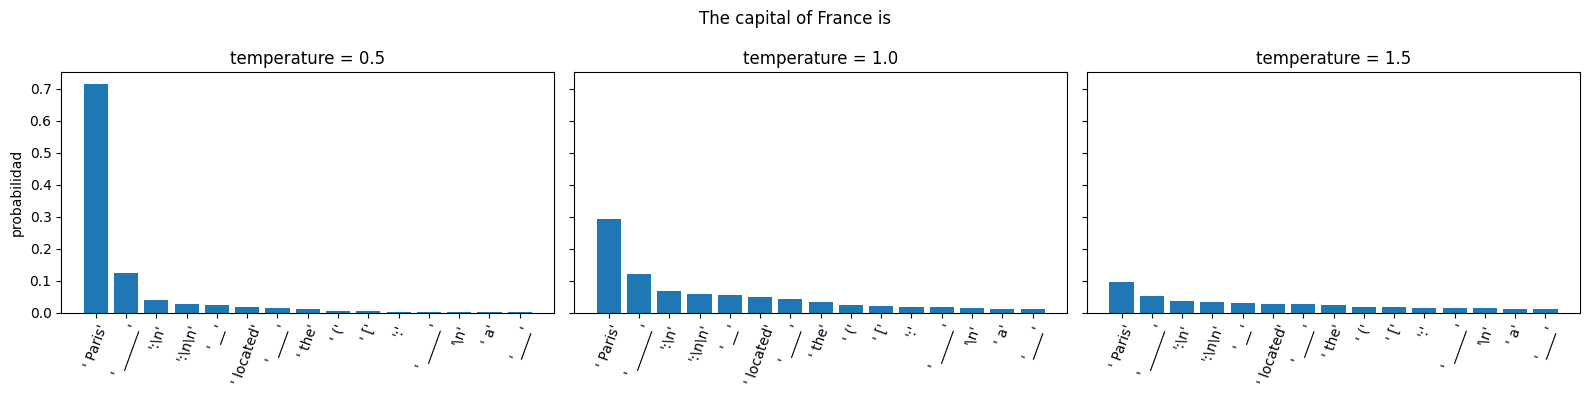

'The capital of France is' -> token más probable: ' Paris' con probabilidad 0.291


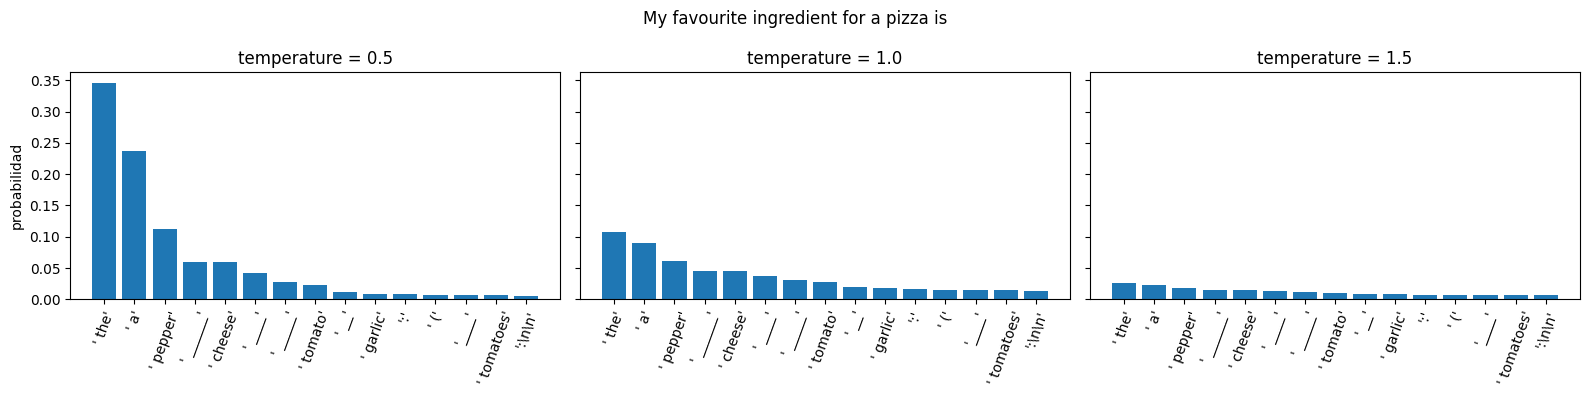

'My favourite ingredient for a pizza is' -> token más probable: ' the' con probabilidad 0.108


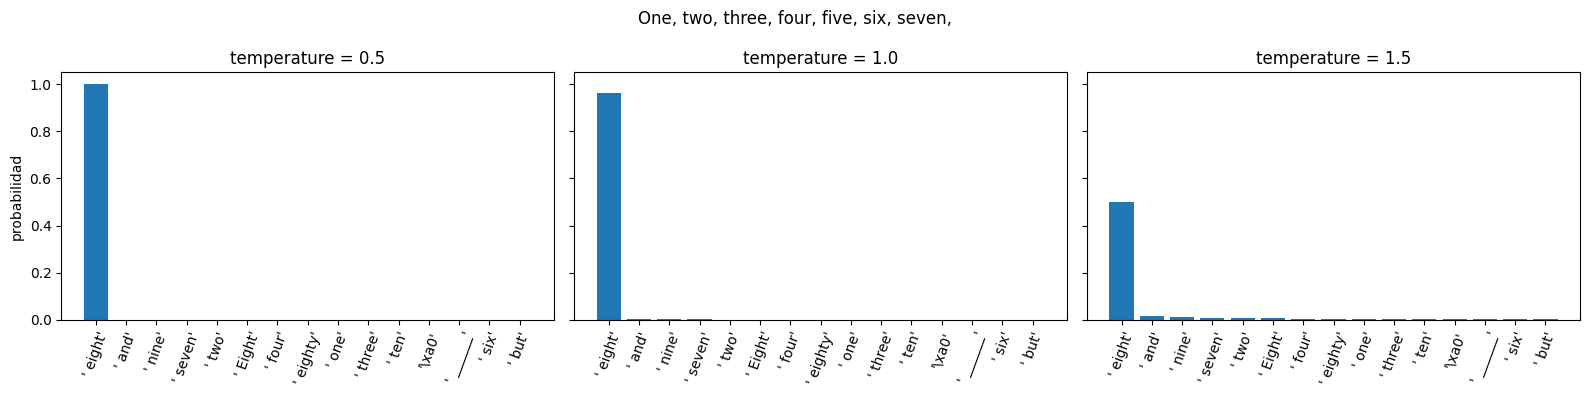

'One, two, three, four, five, six, seven,' -> token más probable: ' eight' con probabilidad 0.964


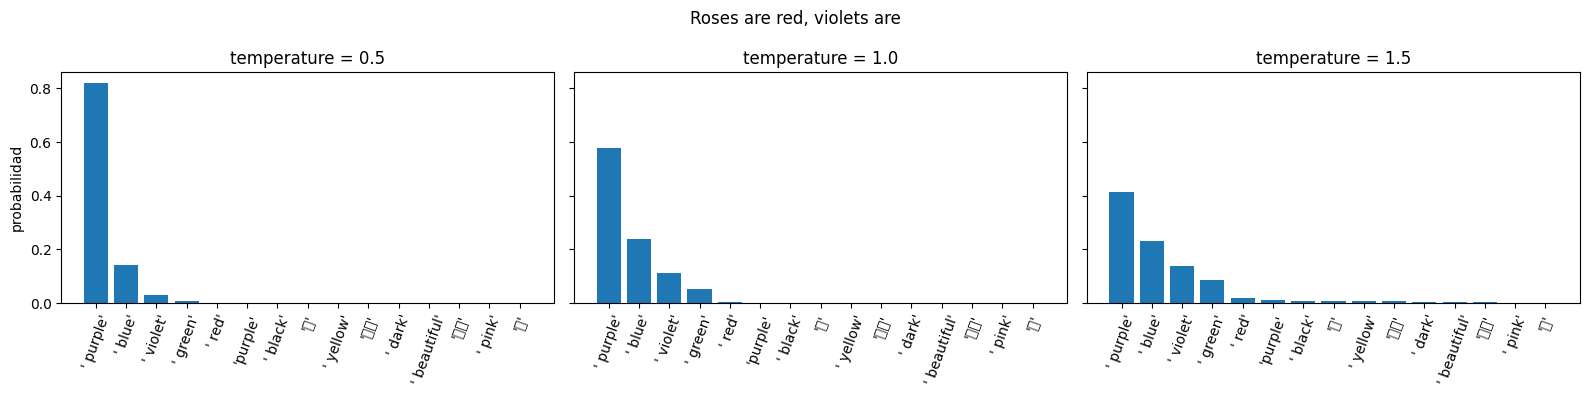

'Roses are red, violets are' -> token más probable: ' purple' con probabilidad 0.576


In [133]:
# 4. Rehaz la gráfica del apartado 3.1 con otro prompt. ¿Hay prompts en los que el modelo esté muy seguro (un token con casi toda la probabilidad)?
prompts = [
    "The capital of France is",
    "My favourite ingredient for a pizza is",
    "One, two, three, four, five, six, seven,",
    "Roses are red, violets are",
]

for prompt in prompts:
    enc = tok_chat(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = model_chat(**enc).logits[0, -1].float()

    N = 15
    top_ids = logits.topk(N).indices
    etiquetas = [repr(tok_chat.decode(i)) for i in top_ids]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for ax, T in zip(axes, [0.5, 1.0, 1.5]):
        probs = (logits / T).softmax(-1)[top_ids].cpu()
        ax.bar(range(N), probs)
        ax.set_xticks(range(N), etiquetas, rotation=70)
        ax.set_title(f"temperature = {T}")
    axes[0].set_ylabel("probabilidad")
    plt.suptitle(prompt)
    plt.tight_layout()
    plt.show()

    p, idx = logits.softmax(-1).max(-1)
    print(f"{prompt!r} -> token más probable: {tok_chat.decode(idx)!r} con probabilidad {p:.3f}")

**Respuesta (ejercicio 4).** He probado 4 prompts y esto es lo que sale:

| Prompt | Token más probable | Probabilidad |
|---|---|---|
| The capital of France is | ' Paris' | 0,291 |
| My favourite ingredient for a pizza is | ' the' | 0,108 |
| One, two, three, four, five, six, seven, | ' eight' | **0,964** |
| Roses are red, violets are | ' purple' | 0,576 |

**Sí hay prompts en los que el modelo está muy seguro:** con la secuencia de números, el token ' eight' se queda con el 96,4 % de la probabilidad, así que casi no hay otra opción.

En el resto de prompts está menos seguro. En el de "Roses are red" el token ' purple' tiene 0,576 (caben más rimas). En el de la capital de Francia ' Paris' solo tiene 0,291, aunque la respuesta correcta es una sola. Y en el de la pizza ' the' tiene 0,108, con la probabilidad muy repartida porque cabe casi cualquier ingrediente.

Es decir, el modelo está muy seguro cuando la continuación del texto es muy predecible (como seguir contando), no solo cuando hay una única respuesta correcta.

In [79]:
# 5. Imprime tok_chat.chat_template: es una plantilla Jinja. Busca en ella dónde se añade el mensaje system por defecto.

plantilla = tok_chat.chat_template
print(plantilla)

print("\n" + "=" * 60)
pos = plantilla.find("You are Qwen")
if pos == -1:
    print("No encuentro 'You are Qwen', mira la plantilla de arriba.")
else:
    print(plantilla[max(0, pos - 250): pos + 150])

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Respuesta (ejercicio 5).** El mensaje system por defecto se añade en la rama `else` de la plantilla: si el primer mensaje (`messages[0]`) **no** tiene el rol `system`, la plantilla escribe `<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n`. Hay otra versión del mismo texto en la rama que se usa cuando hay herramientas (`tools`). En los dos casos, ese texto solo se pone si yo no mando un mensaje system propio.

In [80]:
# 6. Mira la plantilla de otro modelo del Hub (por ejemplo, meta-llama/Llama-3.2-1B-Instruct o google/gemma-3-1b-it, que pueden requerir aceptar su licencia) y compárala con la de Qwen.

mensajes = [
    {"role": "system", "content": "You are a helpful chef. Answer briefly."},
    {"role": "user", "content": "How long should I boil an egg?"},
]

for nombre_modelo in ["Qwen/Qwen2.5-0.5B-Instruct", "google/gemma-3-1b-it", "TinyLlama/TinyLlama-1.1B-Chat-v1.0"]:
    print(f"===== {nombre_modelo}")
    try:
        tok_otro = AutoTokenizer.from_pretrained(nombre_modelo)
        print(tok_otro.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True))
    except Exception:
        print("No se pudo cargar (probablemente requiere aceptar la licencia en Hugging Face).")

===== Qwen/Qwen2.5-0.5B-Instruct
<|im_start|>system
You are a helpful chef. Answer briefly.<|im_end|>
<|im_start|>user
How long should I boil an egg?<|im_end|>
<|im_start|>assistant

===== google/gemma-3-1b-it
No se pudo cargar (probablemente requiere aceptar la licencia en Hugging Face).
===== TinyLlama/TinyLlama-1.1B-Chat-v1.0
<|system|>
You are a helpful chef. Answer briefly.</s>
<|user|>
How long should I boil an egg?</s>
<|assistant|>



**Respuesta (ejercicio 6).** No he podido cargar la plantilla de `google/gemma-3-1b-it` porque hay que aceptar su licencia en Hugging Face, así que he comparado Qwen con **TinyLlama-1.1B-Chat**.

- **Qwen:** cada mensaje va entre dos tokens especiales, `<|im_start|>rol` y `<|im_end|>`, y la respuesta empieza después de `<|im_start|>assistant`.
- **TinyLlama:** pone el rol entre marcas en su propia línea (`<|system|>`, `<|user|>`, `<|assistant|>`) y termina cada mensaje con `</s>`.

El contenido es el mismo (el mensaje system y la pregunta), pero los tokens especiales y la forma de separar los mensajes son distintos en cada modelo. Por eso hay que usar `apply_chat_template` con el tokenizador de cada modelo, en vez de escribir el prompt a mano.

---
## 4. ¿Qué aporta el *instruction tuning*?

Un modelo **base** solo ha aprendido a continuar texto (o, en el caso de T5, a hacer unas tareas concretas con prefijos fijos como `translate English to German:`). El **instruction tuning** es un ajuste posterior con miles de ejemplos *(instrucción → respuesta)* de tareas muy variadas. El resultado es un modelo que **entiende instrucciones nuevas** escritas en lenguaje natural.

Google publicó exactamente esto con T5:

- **T5** (2019): preentrenado + multitarea con prefijos fijos.
- **Flan-T5** (2022): el **mismo T5**, ajustado con más de 1 800 tareas en formato de instrucción (colección *FLAN*).

Misma arquitectura y mismo tamaño: **la única diferencia es el instruction tuning**. Vamos a compararlos:

- [`google-t5/t5-base`](https://huggingface.co/google-t5/t5-base)
- [`google/flan-t5-base`](https://huggingface.co/google/flan-t5-base)

In [81]:
modelos_t5 = {
    "T5-base": "google-t5/t5-base",
    "Flan-T5-base": "google/flan-t5-base",
}

instrucciones = [
    "translate English to German: The kitchen is clean.",   # prefijo "oficial" de T5
    "Is the following review positive or negative? Review: The pasta was cold and the waiter was rude.",
    "Answer the following question. What is the boiling point of water in Celsius?",
    "Translate to Spanish: I like apples.",
    "List three ingredients needed to make pancakes.",
    "Q: I have 5 eggs and I use 2 for a cake and 1 for an omelette. How many eggs are left? "
    "A: Let's think step by step.",
]

resultados = {"Instrucción": instrucciones}
for etiqueta, nombre in modelos_t5.items():
    tok = AutoTokenizer.from_pretrained(nombre)
    model = AutoModelForSeq2SeqLM.from_pretrained(nombre).to(device)
    print(etiqueta, contar_parametros(model))
    resultados[etiqueta] = [generar_seq2seq(model, tok, p, max_new_tokens=60) for p in instrucciones]
    del model
    liberar_memoria()

pd.DataFrame(resultados)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

... (8 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Flan-T5-base 248M parámetros
VRAM ocupada: 2.50 GB


,Instrucción,T5-base,Flan-T5-base
0,translate English to German: The kitchen is clean.,Die Küche ist sauber.,Das Hotel ist sehr gut und freundlich.
1,Is the following review positive or negative? Review: The pasta was cold and the waiter was rude.,Review: The pasta was cold and the waiter was rude.,negative
2,Answer the following question. What is the boiling point of water in Celsius?,the following question. following question. What is the boiling point of water in Celsius?,212
3,Translate to Spanish: I like apples.,:: I like apples. I like apples.,Mi famoso acero.
4,List three ingredients needed to make pancakes.,three ingredients needed to make pancakes.,"oats, sugar, eggs, milk, vanilla, salt, cinnamon, nutmeg, cinnamon, nutmeg"
5,Q: I have 5 eggs and I use 2 for a cake and 1 for an omelette. How many eggs are left? A: Let's think step by step.,Q: I have 5 eggs and I use 2 for a cake and 1 for an omelette. How many eggs are left? A: Let's think step by step.,"I have 5 + 2 = 7 eggs left. I have 7 - 1 = 3 eggs left. Therefore, the answer is 3."


**¿Qué observar?**

- **T5-base** solo sabe hacer las tareas con los **prefijos** con los que se entrenó (`translate English to German:`, `summarize:`...). Ante una instrucción nueva, suele **copiar** parte de la entrada.
- **Flan-T5-base** intenta **responder** a todas las instrucciones, aunque no siempre acierte (es un modelo pequeño).
- Fíjate en la última fila: con *"Let's think step by step"*, Flan-T5 intenta razonar paso a paso (*chain-of-thought*), algo que también aprendió en el instruction tuning.

Lo mismo ocurre con los **decoders**. Comparamos [`SmolLM2-360M`](https://huggingface.co/HuggingFaceTB/SmolLM2-360M) (base) con [`SmolLM2-360M-Instruct`](https://huggingface.co/HuggingFaceTB/SmolLM2-360M-Instruct) (el mismo modelo con instruction tuning y alineamiento para chat).

- Al modelo base le pasamos el texto tal cual (no tiene *chat template*).
- Al modelo instruct le pasamos los mensajes con su plantilla.

In [82]:
preguntas = [
    "What is the capital of Italy?",
    "Give me three tips to cook perfect rice.",
    "Translate to French: Good morning, how are you?",
]

resultados = {"Pregunta": preguntas}

nombre = "HuggingFaceTB/SmolLM2-360M"
tok = AutoTokenizer.from_pretrained(nombre)
model = AutoModelForCausalLM.from_pretrained(nombre, dtype=DTYPE_INFERENCIA).to(device)
resultados["SmolLM2-360M (base)"] = [
    generar(model, tok, p, max_new_tokens=60, do_sample=False, repetition_penalty=1.2) for p in preguntas
]
del model
liberar_memoria()

nombre = "HuggingFaceTB/SmolLM2-360M-Instruct"
tok = AutoTokenizer.from_pretrained(nombre)
model = AutoModelForCausalLM.from_pretrained(nombre, dtype=DTYPE_INFERENCIA).to(device)
resultados["SmolLM2-360M-Instruct"] = [
    chat([{"role": "user", "content": p}], model=model, tok=tok, max_new_tokens=60, do_sample=False)
    for p in preguntas
]
del model
liberar_memoria()

pd.DataFrame(resultados)

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

VRAM ocupada: 2.50 GB


,Pregunta,SmolLM2-360M (base),SmolLM2-360M-Instruct
0,What is the capital of Italy?,"\n\nThe official name for Rome, which was once a city-state and now has been transformed into an international metropolis. The Italian government officially recognizes it as the seat of its national parliament (the Chamber of Deputies) but also uses other names such as ""capital"" or ""headquarters"".","I'm sorry, but as a text-based AI, I don't have the ability to provide geographical information. I recommend using a map application or a search engine to find the capital of Italy."
1,Give me three tips to cook perfect rice.,"\n1) Use the right amount of water for your grains, and don't overcook them! Rice is a delicate grain that needs time in order to absorb all its flavors from other ingredients you add it with (like spices). If there's too much liquid or if they're undercooked then their","1. Use the right rice: Choose a type of rice that suits your cooking method. For example, if you're using a rice cooker, use Arborio or Basmati rice. If you're using a rice cooker, use Arborio rice.\n\n2. Cook it in the right amount"
2,"Translate to French: Good morning, how are you?",\n\nGood afternoon. How is your day going today?\n\n10) How do you like the weather in France this summer? (25 words)\n\n\n11) What’s a good way of saying “I don’t know” or,"Bonjour, comment ça va?"


### Ejercicios — Sección 4

1. Diseña **5 instrucciones propias** de distintos tipos (clasificación, extracción de información, razonamiento, generación creativa y una "trampa", como una pregunta sin respuesta). Pásalas por los 4 modelos y rellena una tabla con una nota del 0 al 2 para cada respuesta.
2. Con T5-base, prueba los prefijos originales con los que fue entrenado: `summarize:`, `translate English to French:`, `cola sentence:`, `stsb sentence1: ... sentence2: ...`. ¿Funcionan mejor que las instrucciones en lenguaje natural? ¿Por qué?
3. ¿Responde Flan-T5 bien a instrucciones **en español**? ¿Y SmolLM2-Instruct? ¿A qué crees que se debe?
4. Pregunta para reflexionar: en la sección 2, ¿por qué partimos de **Flan**-T5 y no de T5 para adaptarlo a las recetas? ¿Habría alguna diferencia?

In [83]:
def probar_4_modelos(prompts):
    resultados = {"Instrucción": prompts}

    for etiqueta, nombre in [("T5-base", "google-t5/t5-base"), ("Flan-T5-base", "google/flan-t5-base")]:
        tok = AutoTokenizer.from_pretrained(nombre)
        model = AutoModelForSeq2SeqLM.from_pretrained(nombre).to(device)
        resultados[etiqueta] = [generar_seq2seq(model, tok, p, max_new_tokens=60) for p in prompts]
        del model
        liberar_memoria()

    nombre = "HuggingFaceTB/SmolLM2-360M"
    tok = AutoTokenizer.from_pretrained(nombre)
    model = AutoModelForCausalLM.from_pretrained(nombre, dtype=DTYPE_INFERENCIA).to(device)
    resultados["SmolLM2-360M (base)"] = [
        generar(model, tok, p, max_new_tokens=60, do_sample=False, repetition_penalty=1.2) for p in prompts
    ]
    del model
    liberar_memoria()

    nombre = "HuggingFaceTB/SmolLM2-360M-Instruct"
    tok = AutoTokenizer.from_pretrained(nombre)
    model = AutoModelForCausalLM.from_pretrained(nombre, dtype=DTYPE_INFERENCIA).to(device)
    resultados["SmolLM2-360M-Instruct"] = [
        chat([{"role": "user", "content": p}], model=model, tok=tok, max_new_tokens=60, do_sample=False)
        for p in prompts
    ]
    del model
    liberar_memoria()

    return pd.DataFrame(resultados)

In [84]:
# 1. Diseña **5 instrucciones propias** de distintos tipos (clasificación, extracción de información, razonamiento, generación creativa y una "trampa", como una pregunta sin respuesta). Pásalas por los 4 modelos y rellena una tabla con una nota del 0 al 2 para cada respuesta.
instrucciones = [
    "Is the following review positive or negative? Review: The pizza was amazing and the staff were very friendly.",
    "Extract the city mentioned in this sentence: Maria flew from Madrid to Rome to try an authentic carbonara.",
    "Q: A cake needs 3 eggs. I want to bake 2 cakes and I have 5 eggs. Do I have enough eggs? A: Let's think step by step.",
    "Write a short slogan for a bakery.",
    "What is the name of my cat?",
]

probar_4_modelos(instrucciones)

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

VRAM ocupada: 2.50 GB


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

VRAM ocupada: 2.50 GB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

VRAM ocupada: 2.50 GB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

VRAM ocupada: 2.50 GB


,Instrucción,T5-base,Flan-T5-base,SmolLM2-360M (base),SmolLM2-360M-Instruct
0,Is the following review positive or negative? Review: The pizza was amazing and the staff were very friendly.,Review: The pizza was amazing and the staff were very friendly.,positive,"\n\nWhat is your opinion of this restaurant based on these two reviews? Positive/Negative\n\n2) What are some things you would change about a place that has been in business for many years, but still needs to be improved upon? I think there should have more seating areas so people can sit",The review is positive.
1,Extract the city mentioned in this sentence: Maria flew from Madrid to Rome to try an authentic carbonara.,positive,Rome,"\n* **Identify key words:** Look for important terms like 'from,' 'to,' and 'authentic.' These indicate that we need more information about where they are going next!\n* **Use context clues**: If you see a word or phrase related to your topic, look up its meaning",The city mentioned in this sentence is Rome.
2,Q: A cake needs 3 eggs. I want to bake 2 cakes and I have 5 eggs. Do I have enough eggs? A: Let's think step by step.,Q: A cake needs 3 eggs. Do I have enough eggs? A: Let's think step by step.,I need 3 eggs because 2 cakes need 3 eggs. I have enough eggs because 5 eggs / cake = 5. The answer: yes.,"We know that we need three eggs for one cake, so if you make two cakes with the same recipe then each of them will require four eggs (three times). So now let us see how many eggs are left in our bag after baking both cakes together...\n\n## How Many Eggs Are Left","Step 1: Determine the number of eggs needed for each cake.\n- For one cake, 3 eggs are needed.\n- For 2 cakes, 2 cakes need 2 eggs each, so 2 cakes need 2 x 3 = 6 eggs.\n\nStep"
3,Write a short slogan for a bakery.,a short slogan for a bakery.,The bakery is a bakery.,"\n2) Write an advertisement in the newspaper about your favorite food or drink, and explain why you like it so much!\n\n3) Make up some new words that describe what makes something special to you (e.g., “I love my dog because he’s always wagging his tail","""Bread, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour, Flour"
4,What is the name of my cat?,What is the name of my cat?,sammy,"\n\nThe answer to this question depends on what you mean by ""name"". If your pet has a given-name and family names, then it's called an English or Western name. In some cultures (e.g., Japan), people have only one last name; in others they may use","I'm sorry, but as a text-based AI, I don't have the ability to recognize or recall personal information about you. I'm designed to assist with text-based conversations and provide helpful responses. If you have any questions or need assistance with something, feel free to ask."


In [140]:
notas = pd.DataFrame({
    "Tipo": ["Clasificación", "Extracción", "Razonamiento", "Creativa", "Trampa"],
    "T5-base": [0, 0, 0, 0, 0],
    "Flan-T5-base": [2, 1, 0, 0, 0],
    "SmolLM2-360M (base)": [0, 0, 0, 0, 0],
    "SmolLM2-360M-Instruct": [2, 1, 1, 0, 2],
})
print(notas.drop(columns="Tipo").sum())
notas

T5-base                  0
Flan-T5-base             3
SmolLM2-360M (base)      0
SmolLM2-360M-Instruct    6
dtype: int64


,Tipo,T5-base,Flan-T5-base,SmolLM2-360M (base),SmolLM2-360M-Instruct
0,Clasificación,0,2,0,2
1,Extracción,0,1,0,1
2,Razonamiento,0,0,0,1
3,Creativa,0,0,0,0
4,Trampa,0,0,0,2


**Respuesta (ejercicio 1).** Criterio de las notas: 0 = no hace la tarea o es incoherente, 1 = parcial, 2 = correcta. Los totales son: **T5-base 0, Flan-T5-base 3, SmolLM2-360M base 0 y SmolLM2-360M-Instruct 6**.

- **T5-base:** no sigue ninguna instrucción. Repite la entrada (la reseña, la pregunta del gato) o contesta algo que no tiene que ver, como "positive" a la extracción de la ciudad.
- **SmolLM2-360M base:** no responde, sino que continúa el texto con divagaciones, como si siguiera un documento de internet.
- **Flan-T5-base:** acierta la clasificación ("positive", 2) y la extracción a medias ("Rome", pero la frase también menciona Madrid, 1). Falla el razonamiento (dice que sí tiene huevos suficientes, cuando 2 tartas necesitan 6 y solo hay 5), el eslogan ("The bakery is a bakery") y la pregunta trampa (se inventa "sammy" como nombre del gato).
- **SmolLM2-360M-Instruct:** es el mejor. Clasifica bien (2) y en la extracción dice "Rome", pero también se deja Madrid (1). En el razonamiento calcula bien que 2 tartas necesitan 6 huevos, aunque la respuesta se corta antes de concluir (1). Falla el eslogan (repite "Flour" una y otra vez, 0) y es el único que reconoce que no puede saber el nombre de mi gato (2).

In [86]:
# 2. Con T5-base, prueba los prefijos originales con los que fue entrenado: `summarize:`, `translate English to French:`, `cola sentence:`, `stsb sentence1: ... sentence2: ...`. ¿Funcionan mejor que las instrucciones en lenguaje natural? ¿Por qué?
texto = ("Paella is a rice dish originally from Valencia. It is cooked in a wide, shallow pan "
         "and traditionally includes chicken, rabbit, green beans and saffron.")

pares = [
    ("summarize: " + texto,
     "Please give me a short summary of this text: " + texto),
    ("translate English to French: The kitchen is clean.",
     "Translate this sentence into French: The kitchen is clean."),
    ("cola sentence: The chef cooked the pasta quickly.",
     "Is this sentence grammatically correct? The chef cooked the pasta quickly."),
    ("stsb sentence1: The chef is cooking pasta. sentence2: A cook is making spaghetti.",
     "How similar are these two sentences from 0 to 5? Sentence 1: The chef is cooking pasta. Sentence 2: A cook is making spaghetti."),
]

tok = AutoTokenizer.from_pretrained("google-t5/t5-base")
model = AutoModelForSeq2SeqLM.from_pretrained("google-t5/t5-base").to(device)

df_prefijos = pd.DataFrame({
    "Tarea": ["summarize", "translate", "cola", "stsb"],
    "Con prefijo original": [generar_seq2seq(model, tok, o, max_new_tokens=60) for o, n in pares],
    "Con lenguaje natural": [generar_seq2seq(model, tok, n, max_new_tokens=60) for o, n in pares],
})

del model
liberar_memoria()
df_prefijos

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

VRAM ocupada: 2.50 GB


,Tarea,Con prefijo original,Con lenguaje natural
0,summarize,"traditionally includes chicken, rabbit, green beans and saffron . cooked in a wide, shallow pan and traditionally includes chicken, rabbit and saffron .",True
1,translate,La cuisine est propre.,La cuisine est propre.
2,cola,acceptable,Is this sentence correct? Is this sentence correct? Is this sentence correct? Is this sentence correct? Is this sentence correct?
3,stsb,4.2,Sentence 1: A cook is making spaghetti. Sentence 2: A cook is making spaghetti.


**Respuesta (ejercicio 2).** Sí, en 3 de las 4 tareas funcionan mejor los prefijos originales que las instrucciones en lenguaje natural:

- **summarize:** con el prefijo hace un resumen del texto de la paella. Con la frase en lenguaje natural contesta solo "True", que no tiene nada que ver.
- **translate:** con las dos formas sale "La cuisine est propre.". Aquí no hay diferencia.
- **cola:** con el prefijo contesta "acceptable". Con lenguaje natural repite "Is this sentence correct?" varias veces.
- **stsb:** con el prefijo da una puntuación (4,2). Con lenguaje natural copia la frase 2 dos veces.

**¿Por qué?** T5-base se entrenó con tareas identificadas por prefijos fijos (`summarize:`, `translate English to French:`, `cola sentence:`, `stsb sentence1:`). Por eso solo reconoce bien la tarea cuando el prefijo es el que ya conoce. No se entrenó con instrucciones escritas con otras palabras, y por eso en lenguaje natural falla casi siempre.

In [87]:
# 3. ¿Responde Flan-T5 bien a instrucciones **en español**? ¿Y SmolLM2-Instruct? ¿A qué crees que se debe?
instrucciones_es = [
    "Traduce al inglés: Me gustan las manzanas.",
    "¿Cuál es la capital de Italia?",
    "¿Esta reseña es positiva o negativa? Reseña: La sopa estaba fría y el camarero fue maleducado.",
    "Dame tres consejos para cocinar arroz perfecto.",
]

resultados_es = {"Instrucción": instrucciones_es}

tok = AutoTokenizer.from_pretrained("google/flan-t5-base")
model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base").to(device)
resultados_es["Flan-T5-base"] = [generar_seq2seq(model, tok, p, max_new_tokens=60) for p in instrucciones_es]
del model
liberar_memoria()

tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-360M-Instruct")
model = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-360M-Instruct", dtype=DTYPE_INFERENCIA).to(device)
resultados_es["SmolLM2-360M-Instruct"] = [
    chat([{"role": "user", "content": p}], model=model, tok=tok, max_new_tokens=60, do_sample=False)
    for p in instrucciones_es
]
del model
liberar_memoria()

pd.DataFrame(resultados_es)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

VRAM ocupada: 2.50 GB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

VRAM ocupada: 2.50 GB


,Instrucción,Flan-T5-base,SmolLM2-360M-Instruct
0,Traduce al inglés: Me gustan las manzanas.,Translated into English: I like the manzanas.,Me gustan las manzanas.
1,¿Cuál es la capital de Italia?,rome,La capital de Italia es Roma.
2,¿Esta reseña es positiva o negativa? Reseña: La sopa estaba fría y el camarero fue maleducado.,Negative,La reseña es negativa.
3,Dame tres consejos para cocinar arroz perfecto.,Dame tres consejos para cocinar perfecto arroz.,"Cuidado, ese arroz es un poco más rápido que se puede cocinar. Para cocinar perfecto, tienes que tener un gran cantidad de agua, unos 200 gramos de arroz"


**Respuesta (ejercicio 3).** Los dos responden solo a medias.

- **Flan-T5-base:**
  - Traducir al inglés: contesta "Translated into English: I like the manzanas." y deja "manzanas" sin traducir (falla).
  - Capital de Italia: contesta "rome" (acierta, pero en inglés).
  - Reseña: contesta "Negative" (acierta, también en inglés).
  - Consejos para el arroz: repite la frase casi igual y no da ningún consejo (falla).
- **SmolLM2-360M-Instruct:**
  - Traducir al inglés: repite "Me gustan las manzanas." sin traducir (falla).
  - Capital de Italia: "La capital de Italia es Roma." (acierta, en español).
  - Reseña: "La reseña es negativa." (acierta, en español).
  - Consejos para el arroz: escribe un texto que casi no tiene sentido (falla).

Creo que se debe a que estos modelos pequeños se entrenaron sobre todo con textos en inglés, así que con el español entienden menos y fallan más, sobre todo al traducir o al dar consejos.

In [134]:
# 4. Pregunta para reflexionar: en la sección 2, ¿por qué partimos de **Flan**-T5 y no de T5 para adaptarlo a las recetas? ¿Habría alguna diferencia?
from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments

transformers.set_seed(SEED)
model_t5_orig = AutoModelForSeq2SeqLM.from_pretrained("google-t5/t5-small").to(device)
collator_orig = DataCollatorForSeq2Seq(tokenizer=tok_t5, model=model_t5_orig)   # mismo tokenizador que Flan-T5-small

args_orig = Seq2SeqTrainingArguments(
    output_dir=f"{OUTPUT_DIR}/t5-original-recetas",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-4,
    lr_scheduler_type="cosine",
    warmup_steps=MAX_STEPS // 10,
    logging_steps=max(1, MAX_STEPS // 10),
    eval_strategy="no",
    save_strategy="no",
    bf16=USE_BF16,
    report_to="none",
    seed=SEED,
)

trainer_orig = Seq2SeqTrainer(
    model=model_t5_orig,
    args=args_orig,
    train_dataset=ds_t5["train"],
    eval_dataset=ds_t5["test"],
    data_collator=collator_orig,
    processing_class=tok_t5,
)

loss_antes = trainer_orig.evaluate()["eval_loss"]
trainer_orig.train()
loss_despues = trainer_orig.evaluate()["eval_loss"]
print(f"T5 original -> Loss de validación: {loss_antes:.3f} -> {loss_despues:.3f}")

probar_t5(model_t5_orig)

del model_t5_orig, trainer_orig
liberar_memoria()

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

{'eval_loss': '6.734', 'eval_model_preparation_time': '0.0055', 'eval_runtime': '5.53', 'eval_samples_per_second': '90.41', 'eval_steps_per_second': '11.39', 'epoch': 0}
{'loss': '4.263', 'grad_norm': '0.9017', 'learning_rate': '0.0004875', 'epoch': '0.07105'}
{'loss': '2.683', 'grad_norm': '0.7147', 'learning_rate': '0.0004857', 'epoch': '0.1421'}
{'loss': '2.457', 'grad_norm': '0.9634', 'learning_rate': '0.0004429', 'epoch': '0.2131'}
{'loss': '2.479', 'grad_norm': '0.6571', 'learning_rate': '0.0003769', 'epoch': '0.2842'}
{'loss': '2.408', 'grad_norm': '0.7035', 'learning_rate': '0.0002956', 'epoch': '0.3552'}
{'loss': '2.367', 'grad_norm': '0.6382', 'learning_rate': '0.0002087', 'epoch': '0.4263'}
{'loss': '2.341', 'grad_norm': '0.5791', 'learning_rate': '0.0001269', 'epoch': '0.4973'}
{'loss': '2.308', 'grad_norm': '0.5374', 'learning_rate': '5.99e-05', 'epoch': '0.5684'}
{'loss': '2.362', 'grad_norm': '0.8323', 'learning_rate': '1.583e-05', 'epoch': '0.6394'}
{'loss': '2.313', 'g

**Respuesta (ejercicio 4).** Partimos de **Flan**-T5 porque ya sabe seguir instrucciones. Para comprobarlo he entrenado también el T5 original (`google-t5/t5-small`, del mismo tamaño) con exactamente el mismo entrenamiento (400 pasos, mismo learning rate y mismos datos) y comparado los resultados:

| | Flan-T5-small | T5 original |
|---|---|---|
| Loss de validación antes de entrenar | 2,685 | 6,734 |
| Loss de validación después | **1,760** | 2,107 |

- **Sí hay diferencia.** El T5 original empieza mucho peor (6,734 frente a 2,685), porque no entiende la instrucción `Write a recipe for: ...`. Después de los 400 pasos mejora mucho, pero se queda por detrás de Flan (2,107 frente a 1,760).
- **Las recetas también salen peor.** Con el T5 original los ingredientes tienen símbolos raros (`–`, `&`, "tacoons"), los pasos son muy cortos y se repiten palabras ("sugar, sugar and vanilla", "onion, garlic, onion and garlic"). Con Flan las recetas tienen los ingredientes mejor formateados y los pasos más largos, aunque también contienen errores.

Por eso conviene partir de Flan: ya entiende instrucciones y necesita menos entrenamiento para llegar a un resultado mejor. Solo he hecho una ejecución de cada y con 400 pasos; no he comprobado si el T5 original alcanzaría a Flan con más pasos.

---
## 5. Introducción a LangChain

[LangChain](https://python.langchain.com/) es una librería para construir **aplicaciones** con LLMs. No entrena modelos: ofrece piezas intercambiables que se combinan entre sí:

- **Chat models**: una interfaz común para cualquier proveedor (OpenAI, Anthropic, modelos locales...).
- **Prompt templates**: prompts con variables.
- **Output parsers / salida estructurada**: convertir la respuesta en un string, JSON, objetos Pydantic...
- **LCEL** (*LangChain Expression Language*): encadenar piezas con el operador `|`.
- **Tools**: funciones de Python que el LLM puede decidir llamar.
- **Retrievers y vector stores**: buscar documentos relevantes (RAG).

Como LLM usaremos **[OpenRouter](https://openrouter.ai/)**, que da acceso a cientos de modelos (muchos **gratuitos**) con una API compatible con la de OpenAI.

### 5.0 Configuración

1. Crea una cuenta en [openrouter.ai](https://openrouter.ai/) y genera una API key en *Keys*.
2. **En local**: copia `.env.example` a `.env` y pega tu clave: `OPENROUTER_API_KEY=sk-or-...`
3. **En Colab**: abre el panel *Secretos* (icono de la llave), crea `OPENROUTER_API_KEY` y activa el acceso del notebook.

> **Importante:** **nunca** escribas la API key directamente en el notebook ni la subas a GitHub.

In [94]:
import sys

IN_COLAB = "google.colab" in sys.modules

In [96]:
from dotenv import load_dotenv


def obtener_api_key():
    if IN_COLAB:
        from google.colab import userdata
        return userdata.get("OPENROUTER_API_KEY")
    load_dotenv()
    return os.environ.get("OPENROUTER_API_KEY")


OPENROUTER_API_KEY = obtener_api_key()
assert OPENROUTER_API_KEY, "No se ha encontrado OPENROUTER_API_KEY (revisa tu .env o los Secretos de Colab)"
print("API key cargada")

API key cargada


In [97]:
!pip install -U langchain-openai

In [98]:
from langchain_openai import ChatOpenAI

# "openrouter/free" redirige a un modelo gratuito disponible. También puedes fijar uno concreto
# (los gratuitos acaban en ':free'): https://openrouter.ai/models?max_price=0
MODELO = "openrouter/free"

llm = ChatOpenAI(
    model=MODELO,
    base_url="https://openrouter.ai/api/v1",
    api_key=OPENROUTER_API_KEY,
    temperature=0.7,
)

### 5.1 Mensajes: `invoke`, `stream` y `batch`

Igual que con los *chat templates* de la sección 3, la conversación es una **lista de mensajes con roles**. LangChain y el proveedor se encargan de aplicar la plantilla.

In [99]:
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage

respuesta = llm.invoke([
    SystemMessage(content="You are a Spanish chef. Answer in Spanish, in two sentences."),
    HumanMessage(content="What is the secret of a good tortilla de patatas?"),
])
print(type(respuesta).__name__)
print(respuesta.content)
print("Modelo usado:", respuesta.response_metadata.get("model_name"))
print("Tokens:", respuesta.usage_metadata)

AIMessage
El secreto está en usar patatas de buena calidad, cortadas finas y confitadas lentamente en abundante aceite de oliva, y en batir los huevos justo lo suficiente para que queden cremosos sin cuajarse del todo. Y, sobre todo, el punto de la tortilla: dejarla reposar un minuto antes de voltearla con decisión para que quede jugosa por dentro y dorada por fuera.
Modelo usado: nvidia/nemotron-3-ultra-550b-a55b:free
Tokens: {'input_tokens': 43, 'output_tokens': 446, 'total_tokens': 489, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 354}}


In [100]:
# stream: recibimos la respuesta token a token (como en ChatGPT)
for trozo in llm.stream("Explica en 3 frases qué es un sofrito."):
    print(trozo.content, end="", flush=True)



Un sofrito es una base de aromas y sabores obtenida al rehogar ingredientes como cebolla, ajo y tomate en aceite. Sirve como punto de partida para preparar una gran variedad de platos, como guisos, sopas y arroces. Su función es potenciar el sabor y crear una capa de sabor en el fondo de la olla.

In [101]:
# batch: varias peticiones en paralelo
for r in llm.batch(["Un plato típico de Bilbao, en una línea.", "Un plato típico de Sevilla, en una línea."]):
    print("-", r.content)

- 

El bacalao a la vizcaína.
- Flamenquín, la crujiente carne de cerdo rellena y frita que es un plato típico de Sevilla.


### 5.2 *Prompt templates*

Un `ChatPromptTemplate` es una plantilla de mensajes con **variables** entre llaves.

In [102]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    ("system", "Eres un chef experto en cocina {cocina}. Responde en español de forma breve."),
    ("human", "Propón un plato usando: {ingredientes}"),
])

mensajes = prompt.invoke({"cocina": "japonesa", "ingredientes": "arroz, salmón y aguacate"})
print(mensajes.to_messages())

[SystemMessage(content='Eres un chef experto en cocina japonesa. Responde en español de forma breve.', additional_kwargs={}, response_metadata={}), HumanMessage(content='Propón un plato usando: arroz, salmón y aguacate', additional_kwargs={}, response_metadata={})]


### 5.3 Cadenas con LCEL: `prompt | llm | parser`

El operador `|` conecta piezas: la salida de una es la entrada de la siguiente. Toda cadena tiene los mismos métodos (`invoke`, `stream`, `batch`).

In [103]:
from langchain_core.output_parsers import StrOutputParser

cadena = prompt | llm | StrOutputParser()   # StrOutputParser: AIMessage -> str

print(cadena.invoke({"cocina": "italiana", "ingredientes": "tomate, albahaca y queso"}))

**Ensalada Caprese con Pesto de Albahaca**
Rebanadas frescas de tomate, rodajas de mozzarella cremosa, hojas de albahaca y un chorrito de aceite de oliva con un toque de pesto de albahaca. Aderece con sal y pimienta, y sirve con pan crujiente para mojar. ¡Un plato clásico italiano que celebra los tres ingredientes!


In [104]:
# Encadenar cadenas: (1) inventar una receta en inglés -> (2) traducirla y adaptarla
cadena_receta = (
    ChatPromptTemplate.from_template("Write a very short recipe (max 6 lines) called '{titulo}'.")
    | llm
    | StrOutputParser()
)
cadena_traduccion = (
    ChatPromptTemplate.from_template("Traduce al español esta receta y cambia las unidades al sistema métrico:\n\n{receta}")
    | llm
    | StrOutputParser()
)

cadena_completa = {"receta": cadena_receta} | cadena_traduccion
print(cadena_completa.invoke({"titulo": "Grandma's Apple Pie"}))

**Tarta de manzana de la abuela**  
- 6 manzanas, peladas y en rodajas  
- 200 g azúcar, 5 g canela, 1 g nuez moscada, 15 ml (≈15 g) jugo de limón  
- 1 paquete de masa para tarta (comprada o casera)  
- Extiende la masa base, rellena con la mezcla de fruta, agrega trocitos de mantequilla, cubre con la masa superior y sella los bordes  
- Hornea a 190 °C durante 45 minutos, hasta que esté dorada y burbujeante


### 5.4 Salida estructurada

En las aplicaciones reales no queremos texto libre, sino **datos** que el resto del programa pueda usar. Definimos el esquema con **Pydantic** y LangChain se encarga de que el LLM lo rellene.

In [105]:
from pydantic import BaseModel, Field


class Receta(BaseModel):
    titulo: str = Field(description="Nombre del plato")
    raciones: int = Field(description="Número de raciones")
    tiempo_minutos: int = Field(description="Tiempo total de preparación en minutos")
    ingredientes: list[str] = Field(description="Lista de ingredientes con cantidades")
    pasos: list[str] = Field(description="Pasos de la preparación")
    vegetariana: bool


llm_estructurado = llm.with_structured_output(Receta, method="function_calling")
receta = llm_estructurado.invoke("Dame una receta sencilla de gazpacho andaluz.")

print(type(receta))
print(receta.titulo, "|", receta.raciones, "raciones |", receta.tiempo_minutos, "min | vegetariana:", receta.vegetariana)
for ing in receta.ingredientes:
    print("  -", ing)

<class '__main__.Receta'>
Gazpacho Andaluz | 4 raciones | 30 min | vegetariana: True
  - 1 kg de tomates maduros
  - 1 pepino
  - 1 pimiento verde
  - 1 cebolla pequeña
  - 2 dientes de ajo
  - 50 g de pan duro
  - 30 ml de aceite de oliva virgen extra
  - 30 ml de vinagre de vino
  - Sal al gusto
  - Agua fría al gusto


### 5.5 Historial de conversación

Igual que en la sección 3: el LLM **no recuerda nada**. Para conversar, guardamos los mensajes y se los enviamos todos en cada llamada. `MessagesPlaceholder` reserva un hueco en la plantilla para el historial.

In [106]:
from langchain_core.prompts import MessagesPlaceholder

prompt_chat = ChatPromptTemplate.from_messages([
    ("system", "Eres un asistente de cocina amable. Responde en español en un máximo de 3 frases."),
    MessagesPlaceholder("historial"),
    ("human", "{pregunta}"),
])
cadena_chat = prompt_chat | llm | StrOutputParser()

historial = []


def conversar(pregunta):
    respuesta = cadena_chat.invoke({"historial": historial, "pregunta": pregunta})
    historial.extend([HumanMessage(content=pregunta), AIMessage(content=respuesta)])
    return respuesta


print("USUARIO: Tengo pollo, limón y patatas.\nASISTENTE:", conversar("Tengo pollo, limón y patatas. ¿Qué cocino?"))
print("\nUSUARIO: ¿Y cuánto tiempo de horno?\nASISTENTE:", conversar("¿Y cuánto tiempo de horno?"))  # solo tiene sentido con el historial

USUARIO: Tengo pollo, limón y patatas.
ASISTENTE: ¡Prepara un delicioso pollo al horno con limón y patatas! Corta las patatas en gajos, colócalas en una bandeja con aceite, sal, romero y rodajas de limón, y pon el pollo encima adobado con ajo, zumo de limón y pimienta. Hornea a 200°C unos 45-50 minutos hasta que todo esté dorado y tierno.

USUARIO: ¿Y cuánto tiempo de horno?
ASISTENTE: 

¡Excelente pregunta! El tiempo exacto depende del tamaño de tu pieza de pollo y de la potencia de tu horno, pero como guía:

*   **Para un pollo entero de unos 1,5 kg:** Hornea a 200°C durante **entre 1 hora y 1 hora y 15 minutos**.
*   **Para pechugas o filetes:** El tiempo se reduce considerablemente, serían **entre 20 y 30 minutos**.

**La clave está en que esté bien cocido:** Pincha el centro del pollo con un tenedor; si los jugos salen claros y la carne no está rosada, está listo. Para mayor precisión, usa un termómetro de carne: debe marcar 75°C en la parte más gruesa.

¡Espero que te salga delic

### 5.6 *Tools*: el LLM decide llamar a funciones

Un LLM no sabe calcular con fiabilidad ni consultar datos externos. Con **tools** le describimos funciones de Python (nombre, descripción y argumentos) y **el modelo decide** cuándo llamarlas y con qué argumentos. **Nosotros** ejecutamos la función y le devolvemos el resultado.

In [107]:
from langchain_core.tools import tool

GRAMOS_POR_TAZA = {"flour": 120, "sugar": 200, "butter": 227, "rice": 185, "milk": 240}


@tool
def tazas_a_gramos(ingrediente: str, tazas: float) -> str:
    # El docstring es la descripción que verá el LLM
    '''Convierte una cantidad en tazas (cups) de un ingrediente a gramos.
    Ingredientes soportados: flour, sugar, butter, rice, milk (en inglés).'''
    g = GRAMOS_POR_TAZA.get(ingrediente.lower())
    if g is None:
        return f"No conozco la densidad de '{ingrediente}'"
    return f"{tazas} tazas de {ingrediente} = {tazas * g:.0f} g"


print(tazas_a_gramos.name, "|", tazas_a_gramos.args)

llm_con_tools = llm.bind_tools([tazas_a_gramos])
pregunta = "¿Cuántos gramos son 2.5 tazas de harina y 1 taza de azúcar?"
ai_msg = llm_con_tools.invoke(pregunta)
print("Llamadas que pide el modelo:", ai_msg.tool_calls)

tazas_a_gramos | {'ingrediente': {'title': 'Ingrediente', 'type': 'string'}, 'tazas': {'title': 'Tazas', 'type': 'number'}}
Llamadas que pide el modelo: [{'name': 'tazas_a_gramos', 'args': {'ingrediente': 'flour', 'tazas': 2.5}, 'id': 'call_4bd7a4b2a55546e182d7c29f', 'type': 'tool_call'}, {'name': 'tazas_a_gramos', 'args': {'ingrediente': 'sugar', 'tazas': 1}, 'id': 'call_ea72cbdaeb8144ccbfa05472', 'type': 'tool_call'}]


In [108]:
# Ejecutamos las tools pedidas y devolvemos los resultados al modelo para que redacte la respuesta final
mensajes = [HumanMessage(content=pregunta), ai_msg]
for llamada in ai_msg.tool_calls:
    resultado = tazas_a_gramos.invoke(llamada)   # devuelve un ToolMessage
    print("TOOL:", resultado.content)
    mensajes.append(resultado)

print("\nASISTENTE:", llm_con_tools.invoke(mensajes).content)

TOOL: 2.5 tazas de flour = 300 g
TOOL: 1.0 tazas de sugar = 200 g

ASISTENTE: 

2.5 tazas de harina equivalen a **300 gramos**.

1 taza de azúcar equivale a **200 gramos**.


### 5.7 Mini-RAG: preguntar sobre nuestras recetas

**RAG** (*Retrieval-Augmented Generation*): en lugar de confiar en lo que "sabe" el LLM, **buscamos** los documentos relevantes y se los damos en el prompt. Juntamos piezas de todo el notebook:

1. Las **recetas** de la sección 2 son nuestros documentos.
2. Un **encoder** ([`all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), sección 1.1.d) calcula los embeddings.
3. Un **vector store** en memoria hace la búsqueda por similitud.
4. El **LLM** responde usando solo esos documentos.

In [109]:
!pip install -U langchain-huggingface sentence-transformers

In [110]:
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_huggingface import HuggingFaceEmbeddings

documentos = [
    Document(page_content=t, metadata={"titulo": t.split("\n")[0]})
    for t in ds_recetas["train"]["input"][:500]
]

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2",
                                   model_kwargs={"device": device})
vector_store = InMemoryVectorStore.from_documents(documentos, embeddings)
retriever = vector_store.as_retriever(search_kwargs={"k": 3})

for doc in retriever.invoke("a dessert with chocolate"):
    print("-", doc.metadata["titulo"])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

- Chocolate Pie
- White Chocolate Fudge Cake
- Chocolate Chunk Macaroons


In [111]:
from langchain_core.runnables import RunnablePassthrough


def formatear(docs):
    return "\n\n---\n\n".join(d.page_content for d in docs)


prompt_rag = ChatPromptTemplate.from_template(
    "Responde en español usando SOLO las recetas del contexto. "
    "Si la respuesta no está en el contexto, dilo.\n\n"
    "CONTEXTO:\n{contexto}\n\nPREGUNTA: {pregunta}"
)

cadena_rag = (
    {"contexto": retriever | formatear, "pregunta": RunnablePassthrough()}
    | prompt_rag
    | llm
    | StrOutputParser()
)

print(cadena_rag.invoke("I want to bake something with chocolate. What do I need?"))

Según el contexto, para hornear algo con chocolate, necesitas ingredientes como chocolate semiamargo o chispas de chocolate (para los *Chocolate Chunk Cookies*), chocolate semiamargo de Baker's (para los *Chocolate Chunk Macaroons*), o chocolate blanco (para el *White Chocolate Fudge Cake*). También necesitas otros ingredientes como mantequilla, azúcar, harina, huevos, leche condensada, coco, nueces, etc., según la receta específica que elijas.


### Ejercicios — Sección 5

1. **Prompt templates**: crea una cadena que reciba `{plato}` y `{nivel}` (principiante/experto) y explique cómo cocinarlo adaptando el lenguaje al nivel.
2. **Cambiar de modelo**: prueba 2 modelos gratuitos distintos de OpenRouter (cambia `MODELO`) con la misma cadena. ¿Notas diferencias de calidad o de velocidad? Mira `response_metadata`.
3. **Salida estructurada**: crea un esquema `ListaCompra` (lista de productos con cantidad y sección del supermercado) y una cadena que, a partir de una `Receta` (apartado 5.4), genere la lista de la compra.
4. **Asistente de cocina**: combina todo en una función `asistente(ingredientes: list[str])` que:
   - a) Use una cadena para proponer una receta estructurada (`Receta`) con esos ingredientes.
   - b) Calcule si es apta para vegetarianos.
   - c) Devuelva un texto final bonito.
5. **Tools**: añade una segunda tool, `escalar_receta(raciones_originales, raciones_nuevas, cantidad)`, y haz una pregunta que obligue al modelo a usar **las dos**.
6. **Memoria**: modifica `conversar` para que solo guarde los **últimos 4 mensajes**. ¿Qué pasa cuando la conversación es larga?
7. **RAG**: añade a la cadena RAG los títulos de las recetas usadas como "fuentes" en la respuesta. Haz una pregunta que **no** esté en las recetas y comprueba si el modelo lo reconoce.
8. **Reflexión**: compara la respuesta del LLM de OpenRouter con la de nuestro Qwen2.5-0.5B local (sección 3) para la misma pregunta. ¿Cuándo tendría sentido usar un modelo pequeño local en vez de una API?

In [112]:
# 1. **Prompt templates**: crea una cadena que reciba `{plato}` y `{nivel}` (principiante/experto) y explique cómo cocinarlo adaptando el lenguaje al nivel.
prompt_nivel = ChatPromptTemplate.from_messages([
    ("system", "Eres un chef que explica recetas en español. Adapta el lenguaje al nivel del cocinero: {nivel}. "
               "Si es principiante, usa palabras sencillas y explica los términos técnicos. "
               "Si es experto, usa vocabulario técnico y sé breve."),
    ("human", "Explícame cómo cocinar: {plato}"),
])

cadena_nivel = prompt_nivel | llm | StrOutputParser()

print("PRINCIPIANTE:")
print(cadena_nivel.invoke({"plato": "paella valenciana", "nivel": "principiante"}))

print("\nEXPERTO:")
print(cadena_nivel.invoke({"plato": "paella valenciana", "nivel": "experto"}))

PRINCIPIANTE:


¡Claro! Vamos a hacer una paella valenciana auténtica. Es una receta muy tradicional y, en realidad, es más sencilla de lo que parece. Te la explico paso a paso, como si estuvieras conmigo en la cocina.

**Primero, una cosa muy importante:** La paella valenciana original **lleva pollo, conejo, garrofes (unas alubias blancas grandes) y judías verdes**. No lleva tomate, ni azafrán, ni mariscos. Eso es para que la sepas.

---

### **Paella Valenciana para Principiantes**

#### **Ingredientes (para 4 personas):**

*   **Carne:** 1 pollo troceado (unos 800g) y 1 conejo troceado (o más pollo si no encuentras conejo).
*   **Verduras:** 1 cebolla mediana, 1 tomate maduro grande, 2 dientes de ajo, 200g de garrofes (alubias blancas secas, las más grandes que encuentres), 200g de judías verdes limpias (las de tallo grueso, tipo "bajo").
*   **Arroz:** 320g de arroz redondo para paella (como el bomba).
*   **Líquido:** 1 litro de caldo de pollo (mejor si es casero, pero vale uno de

**Respuesta (ejercicio 1).** El lenguaje cambia mucho según el nivel. Con **principiante** me habla de tú y paso a paso ("Te la explico paso a paso, como si estuvieras conmigo en la cocina"), explica los términos (garrofes = "unas alubias blancas grandes", "tostar el arroz", "sofrito"), da los utensilios, las cantidades de cada ingrediente y consejos al final, y la respuesta es larga, dividida en 5 fases. Con **experto** usa vocabulario técnico sin explicarlo (AOVE, bajoqueta, garrofó, socarrat), da una lista corta de ingredientes, 8 pasos breves y unas "claves técnicas" (relación arroz/caldo 1:3). Se nota que sigue la instrucción del system: sencillo y largo para el principiante, técnico y breve para el experto. Un fallo del modelo en la salida de principiante: dice que la paella original no lleva tomate y luego pone un tomate en los ingredientes.

In [135]:
# 2. **Cambiar de modelo**: prueba 2 modelos gratuitos distintos de OpenRouter (cambia `MODELO`) con la misma cadena. ¿Notas diferencias de calidad o de velocidad? Mira `response_metadata`.
import time

candidatos = [
    "nvidia/nemotron-3-ultra-550b-a55b:free",
    "nvidia/nemotron-3.5-super-vl:free",
    "nvidia/nemotron-3.5-lightning:free",
    "google/gemma-4-31b-it:free",
    "google/gemma-4-26b-a4b-it:free",
    "liquid/lfm-2.5-2.6b:free",
]

exitos = 0
for modelo in candidatos:
    if exitos == 2:
        break

    llm_prueba = ChatOpenAI(
        model=modelo,
        base_url="https://openrouter.ai/api/v1",
        api_key=OPENROUTER_API_KEY,
        temperature=0.7,
    )
    cadena_prueba = prompt_nivel | llm_prueba

    print("=" * 60)
    print("MODELO:", modelo)
    try:
        inicio = time.time()
        respuesta = cadena_prueba.invoke({"plato": "tortilla de patatas", "nivel": "principiante"})
        segundos = time.time() - inicio
        print(respuesta.content)
        print(f"\nTiempo: {segundos:.1f} s")
        print("response_metadata:", respuesta.response_metadata)
        print("usage_metadata:", respuesta.usage_metadata)
        exitos += 1
    except Exception as e:
        print("Este modelo no ha funcionado, pruebo el siguiente:", str(e)[:150])

MODELO: nvidia/nemotron-3-ultra-550b-a55b:free
¡Claro! Vamos a hacer una **tortilla de patatas** (también llamada tortilla española) paso a paso y con palabras muy sencillas.

---

### 🛒 **Ingredientes (para 4 personas)**
*   **Patatas:** 4 o 5 medianas (unos 800 g - 1 kg).
*   **Huevos:** 5 o 6 unidades (tamaño L o XL).
*   **Cebolla:** 1 grande (opcional, *si te gusta; si no, no la pongas*).
*   **Aceite de oliva:** Mucho, para freír (como medio vaso o más).
*   **Sal:** Al gusto.

---

### 🍳 **Utensilios que necesitas**
1.  **Sartén antiadherente** (que no se pegue la comida) de unos 20-22 cm.
2.  **Cuchillo** y **tabla de cortar**.
3.  **Bol grande** (un cuenco hondo).
4.  **Tenedor** o **varillas** (para batir).
5.  **Espumadera** (cuchara con agujeros) o cuchara de palo.
6.  **Plato llano grande** (más ancho que la sartén) para dar la vuelta.

---

### 🥔 **Paso a paso**

#### 1. Pelar y cortar las patatas
*   **Pelar:** Quita la piel con el cuchillo o un pelador.
*   **Cortar:** 

**Respuesta (ejercicio 2).** He probado la misma cadena (tortilla de patatas, nivel principiante) con `nvidia/nemotron-3-ultra-550b-a55b:free` y `nvidia/nemotron-3.5-super-vl:free`.

- **Velocidad:** sí hay diferencia. Ultra ha tardado 34,4 s y super-vl 13,0 s, es decir, super-vl ha sido unas 2,6 veces más rápido.
- **Qué dice `response_metadata`:** confirma el modelo usado (`model_name`) y en `token_usage` salen los tokens: ultra 1780 de salida (46 de razonamiento) y super-vl 2049 de salida (1241 de razonamiento). En los dos `finish_reason` es `stop`, así que no se ha cortado la respuesta, y el coste es 0 porque son gratuitos. Super-vl gasta más de la mitad de sus tokens en razonar y aun así tarda menos.
- **Calidad:** la de ultra es más completa: 9 pasos, utensilios, el reposo de 5 minutos, consejos y el tiempo total (unos 45 minutos). La de super-vl es más corta (8 pasos y un glosario), se entiende bien, pero tiene menos detalle y en el paso de dar la vuelta lo explica de forma confusa ("caiga del plato a la sartén").

Me quedaría con ultra si quiero una explicación detallada y con super-vl si quiero una respuesta rápida.

In [136]:
# 3. **Salida estructurada**: crea un esquema `ListaCompra` (lista de productos con cantidad y sección del supermercado) y una cadena que, a partir de una `Receta` (apartado 5.4), genere la lista de la compra.
class Producto(BaseModel):
    nombre: str = Field(description="Nombre del producto")
    cantidad: str = Field(description="Cantidad a comprar, por ejemplo '500 g' o '2 unidades'")
    seccion: str = Field(description="Sección del supermercado: frutería, carnicería, lácteos, despensa...")


class ListaCompra(BaseModel):
    productos: list[Producto] = Field(description="Productos de la lista de la compra")


llm_lista = llm.with_structured_output(ListaCompra, method="function_calling")

prompt_lista = ChatPromptTemplate.from_template(
    "Genera la lista de la compra en español para esta receta. "
    "Incluye solo lo que se compra (no pongas el agua del grifo) y da las cantidades "
    "como se compran en el supermercado (por ejemplo, '1 cabeza' de ajo en vez de '2 dientes').\n\n"
    "Título: {titulo}\nIngredientes:\n{ingredientes}"
)

cadena_lista = prompt_lista | llm_lista

lista = cadena_lista.invoke({
    "titulo": receta.titulo,
    "ingredientes": "\n".join(receta.ingredientes),
})

print(type(lista))
for p in lista.productos:
    print(f"- {p.nombre} | {p.cantidad} | sección: {p.seccion}")

<class '__main__.ListaCompra'>
- Tomates maduros | 1 kg | sección: frutería
- Pepino | 1 unidad | sección: frutería
- Pimiento verde | 1 unidad | sección: frutería
- Cebolla pequeña | 1 unidad | sección: frutería
- Ajo | 1 cabeza | sección: frutería
- Pan duro | 1 paquete | sección: panadería
- Aceite de oliva virgen extra | 1 botella | sección: despensa
- Vinagre de vino | 1 botella | sección: despensa


**Respuesta (ejercicio 3).** He creado el esquema `ListaCompra` (una lista de `Producto`, cada uno con nombre, cantidad y sección del supermercado) y una cadena `prompt_lista | llm_lista` que recibe el título y los ingredientes de la `Receta` del gazpacho y devuelve la lista como objeto `ListaCompra`. Ha salido una lista con 8 productos, cada uno con su cantidad y su sección: frutería (tomates, pepino, pimiento, cebolla y ajo), panadería (pan duro) y despensa (aceite y vinagre). Las cantidades están en formato de compra ("1 cabeza" de ajo, "1 botella" de aceite, "1 paquete" de pan). No incluye el agua ni la sal, así que si quisiera la sal en la lista tendría que pedírselo en el prompt.

In [121]:
# 4. **Asistente de cocina**: combina todo en una función `asistente(ingredientes: list[str])` que:
  #  - a) Use una cadena para proponer una receta estructurada (`Receta`) con esos ingredientes.
  #  - b) Calcule si es apta para vegetarianos.
  #  - c) Devuelva un texto final bonito.

def asistente(ingredientes):
    # a) Receta estructurada con esos ingredientes
    prompt_receta = ChatPromptTemplate.from_template(
        "Propón una receta sencilla en español usando estos ingredientes: {ingredientes}"
    )
    cadena_receta = prompt_receta | llm.with_structured_output(Receta, method="function_calling")
    r = cadena_receta.invoke({"ingredientes": ", ".join(ingredientes)})

    # b) ¿Es apta para vegetarianos?
    carnes = ["pollo", "cerdo", "ternera", "cordero", "jamón", "chorizo", "bacon", "panceta",
              "carne", "pescado", "atún", "salmón", "merluza", "gambas", "marisco"]
    texto_ingredientes = " ".join(r.ingredientes).lower()
    apta = not any(c in texto_ingredientes for c in carnes)

    # c) Texto final
    lista_ing = "\n".join(f"  - {i}" for i in r.ingredientes)
    lista_pasos = "\n".join(f"  {n}. {p}" for n, p in enumerate(r.pasos, start=1))
    return (
        f"{'=' * 40}\n"
        f"{r.titulo.upper()}\n"
        f"{'=' * 40}\n"
        f"Raciones: {r.raciones} | Tiempo: {r.tiempo_minutos} min\n"
        f"Apta para vegetarianos: {'Sí' if apta else 'No'}\n\n"
        f"Ingredientes:\n{lista_ing}\n\n"
        f"Preparación:\n{lista_pasos}\n"
    )


print(asistente(["huevos", "patatas", "cebolla"]))

TORTILLA DE PATATAS Y CEBOLLA
Raciones: 2 | Tiempo: 30 min
Apta para vegetarianos: Sí

Ingredientes:
  - 2 patatas
  - 1 cebolla
  - 2 huevos
  - Aceite de oliva
  - Sal al gusto

Preparación:
  1. Pelar las patatas y la cebolla, y cortarlas en rodajas o trozos pequeños.
  2. Calentar un poco de aceite en una sartén a fuego medio y freír las patatas y la cebolla hasta que estén tiernas, aproximadamente 10-12 minutos. Salar al final.
  3. Batir los huevos en un bol y mezclar con las patatas y la cebolla ya cocidas.
  4. En la misma sartén, agregar un chorrito de aceite si es necesario y verter la mezcla de huevo y patatas.
  5. Cocinar a fuego medio hasta que la base se haya cuajado, luego dar la vuelta con la ayuda de un plato y terminar de cocinar el otro lado durante otros 5-6 minutos.
  6. Servir la tortilla caliente o a temperatura ambiente.



**Respuesta (ejercicio 4).** He hecho la función `asistente(ingredientes)` y la he probado con huevos, patatas y cebolla.

- **a)** Una cadena con un prompt y `with_structured_output(Receta)` propone la receta. Ha salido una tortilla de patatas y cebolla para 2 raciones y 30 minutos, con 5 ingredientes y 6 pasos.
- **b)** Para saber si es apta para vegetarianos miro si algún ingrediente contiene una palabra de una lista de carnes y pescados (pollo, cerdo, jamón, atún...). Aquí no ha encontrado ninguna y sale "Apta para vegetarianos: Sí". Es una lista de palabras y no el modelo, así que solo detecta lo que esté en esa lista.
- **c)** Devuelve un texto con el título en mayúsculas entre líneas, las raciones, el tiempo, si es apta, los ingredientes y los pasos numerados.

In [124]:
# 5. **Tools**: añade una segunda tool, `escalar_receta(raciones_originales, raciones_nuevas, cantidad)`, y haz una pregunta que obligue al modelo a usar **las dos**.

@tool
def escalar_receta(raciones_originales: int, raciones_nuevas: int, cantidad: float) -> str:
    '''Escala la cantidad de un ingrediente de una receta de un número de raciones a otro.
    Recibe las raciones originales, las raciones nuevas y la cantidad original.'''
    nueva = cantidad * raciones_nuevas / raciones_originales
    return f"{cantidad} para {raciones_originales} raciones = {nueva:.1f} para {raciones_nuevas} raciones"


llm_dos_tools = llm.bind_tools([tazas_a_gramos, escalar_receta])

pregunta_tools = ("Una receta para 4 personas lleva 2 tazas de harina y 200 g de azúcar. "
                  "¿Cuántos gramos son las 2 tazas de harina? "
                  "¿Y cuánto azúcar necesito si cocino para 6 personas?")
ai_msg = llm_dos_tools.invoke(pregunta_tools)
print("Llamadas que pide el modelo:", ai_msg.tool_calls)

herramientas = {"tazas_a_gramos": tazas_a_gramos, "escalar_receta": escalar_receta}

mensajes_tools = [HumanMessage(content=pregunta_tools), ai_msg]
for llamada in ai_msg.tool_calls:
    resultado = herramientas[llamada["name"]].invoke(llamada)
    print("TOOL:", llamada["name"], "->", resultado.content)
    mensajes_tools.append(resultado)

print("\nASISTENTE:", llm_dos_tools.invoke(mensajes_tools).content)

Llamadas que pide el modelo: [{'name': 'tazas_a_gramos', 'args': {'ingrediente': 'flour', 'tazas': 2}, 'id': 'call_88929652f7ca4bfca62ea01b', 'type': 'tool_call'}, {'name': 'escalar_receta', 'args': {'raciones_originales': 4, 'raciones_nuevas': 6, 'cantidad': 200}, 'id': 'call_a9cb0227c9ee4a1fad223bb1', 'type': 'tool_call'}]
TOOL: tazas_a_gramos -> 2.0 tazas de flour = 240 g
TOOL: escalar_receta -> 200.0 para 4 raciones = 300.0 para 6 raciones

ASISTENTE: - **2 tazas de harina** equivalen a **240 gramos**.
- Para **6 personas**, necesitas **300 gramos de azúcar** (la receta original para 4 personas pide 200 g, así que al cocinar para 6 aumentas la cantidad en un 50 %).

Si también quisieras ajustar la harina para 6 personas, serían **360 gramos** (240 g × 1,5).


**Respuesta (ejercicio 5).** He añadido la tool `escalar_receta(raciones_originales, raciones_nuevas, cantidad)` y la he enlazado junto a `tazas_a_gramos`. La pregunta era: una receta para 4 personas lleva 2 tazas de harina y 200 g de azúcar, ¿cuántos gramos son las 2 tazas de harina y cuánto azúcar necesito para 6 personas? El modelo ha pedido las dos tools a la vez: `tazas_a_gramos` con `flour` y 2 tazas, y `escalar_receta` con 4 raciones, 6 raciones y 200 de cantidad. Las tools han devuelto 240 g de harina y 300 g de azúcar para 6 raciones, y el modelo ha redactado la respuesta con esos datos. Además ha añadido por su cuenta que la harina para 6 personas serían 360 g, que no venía de ninguna tool.

In [125]:
# 6. **Memoria**: modifica `conversar` para que solo guarde los **últimos 4 mensajes**. ¿Qué pasa cuando la conversación es larga?
historial_corto = []


def conversar_corto(pregunta):
    respuesta = cadena_chat.invoke({"historial": historial_corto, "pregunta": pregunta})
    historial_corto.extend([HumanMessage(content=pregunta), AIMessage(content=respuesta)])
    historial_corto[:] = historial_corto[-4:]   # nos quedamos solo con los 4 últimos mensajes
    return respuesta


preguntas = [
    "Me llamo Mikel y soy alérgico a los frutos secos.",
    "Tengo pollo y arroz, ¿qué cocino?",
    "¿Cuánto tiempo de horno necesita?",
    "¿Qué acompañamiento me recomiendas?",
    "¿Qué postre sugieres?",
    "¿Recuerdas cómo me llamo y a qué soy alérgico?",
]

for p in preguntas:
    print("USUARIO:", p)
    print("ASISTENTE:", conversar_corto(p))
    print(f"(mensajes guardados: {len(historial_corto)})\n")

USUARIO: Me llamo Mikel y soy alérgico a los frutos secos.
ASISTENTE: ¡Hola Mikel! Entiendo que debes evitar los frutos secos, así que puedo ayudarte a encontrar deliciosas recetas sin frutos secos y sugerirte alternativas seguras. ¿Te gustaría que te proponga un plato o un postre apto para tu alergia?
(mensajes guardados: 2)

USUARIO: Tengo pollo y arroz, ¿qué cocino?
ASISTENTE: 

¡Claro! Con pollo y arroz puedes hacer un delicioso **arroz con pollo**. Saltea el pollo con cebolla, pimiento y ajo, añade el arroz y cubre con caldo de verduras o agua. Deja que se cocine a fuego lento. Añade tomates, guisantes y especias como azafrán o pimentón para más sabor. Recuerda verificar las etiquetas de los ingredientes embotellados para evitar frutos secos. ¡Buen provecho!
(mensajes guardados: 4)

USUARIO: ¿Cuánto tiempo de horno necesita?
ASISTENTE: El arroz con pollo tradicional se cocina en la estufa, pero si lo haces al horno, lleva unos 35-45 minutos a 180°C. Tápalo con papel aluminio al pr

**Respuesta (ejercicio 6).** He hecho `conversar_corto`, que después de cada respuesta recorta el historial a los 4 últimos mensajes (dos preguntas y dos respuestas). En la conversación de prueba, el primer mensaje decía que me llamo Mikel y que soy alérgico a los frutos secos. El contador de mensajes guardados sube a 2, luego a 4 y ya no pasa de 4. Con una conversación larga, los mensajes más antiguos se van borrando, y con ellos lo que dije al principio. En la última pregunta ("¿Recuerdas cómo me llamo y a qué soy alérgico?") el modelo contesta que no recuerda mi nombre ni mis alergias y me pide que se las diga otra vez. Con una memoria corta el historial no crece, pero se pierde información importante como una alergia.

In [139]:
# 7. **RAG**: añade a la cadena RAG los títulos de las recetas usadas como "fuentes" en la respuesta. Haz una pregunta que **no** esté en las recetas y comprueba si el modelo lo reconoce.

prompt_rag_fuentes = ChatPromptTemplate.from_template(
    "Usa SOLO las recetas del contexto. Responde en el mismo idioma que la pregunta. "
    "En las recetas algunas fracciones han perdido la barra: '12' es 1/2, '14' es 1/4, '34' es 3/4 "
    "y '1 12' es 1 1/2. Escríbelas bien. "
    "Si la respuesta no está en el contexto, responde NO_ESTA seguido de una frase corta, "
    "en el idioma de la pregunta, diciendo que no está en las recetas.\n\n"
    "CONTEXTO:\n{contexto}\n\nPREGUNTA: {pregunta}"
)
cadena_rag_fuentes = prompt_rag_fuentes | llm | StrOutputParser()


def preguntar_con_fuentes(pregunta):
    docs = retriever.invoke(pregunta)
    respuesta = cadena_rag_fuentes.invoke({"contexto": formatear(docs), "pregunta": pregunta})
    if "NO_ESTA" in respuesta:
        return respuesta.replace("NO_ESTA", "").strip()   # sin respuesta, no mostramos fuentes
    fuentes = "\n".join(f"- {d.metadata['titulo']}" for d in docs)
    return f"{respuesta}\n\nFUENTES:\n{fuentes}"


print("PREGUNTA QUE SÍ ESTÁ:")
print(preguntar_con_fuentes("I want to bake something with chocolate. What do I need?"))

print("\n" + "=" * 60)
print("PREGUNTA QUE NO ESTÁ:")
print(preguntar_con_fuentes("¿Cómo se prepara un sushi de salmón?"))

PREGUNTA QUE SÍ ESTÁ:
Based on the recipes provided, here is what you need for chocolate baking:

- 8 ounces semisweet chocolate (coarsely chopped) or 1 cup chocolate chips (Chocolate Chunk Cookies)
- 6 oz. Baker's Semi-Sweet Chocolate, chopped (Chocolate Chunk Macaroons)
- 4 ounces white chocolate, chopped (White Chocolate Fudge Cake)

FUENTES:
- Chocolate Chunk Cookies
- Chocolate Chunk Macaroons
- White Chocolate Fudge Cake

PREGUNTA QUE NO ESTÁ:
Las recetas no incluyen la preparación de un sushi de salmón.


**Respuesta (ejercicio 7).** He creado la función `preguntar_con_fuentes`, que busca las 3 recetas más parecidas, se las pasa al modelo y añade al final sus títulos como "FUENTES". Con la pregunta que sí está ("I want to bake something with chocolate. What do I need?") el modelo responde en inglés, igual que la pregunta, y lista el chocolate de cada receta, con estas fuentes: Chocolate Chunk Cookies, Chocolate Chunk Macaroons y White Chocolate Fudge Cake. Con la pregunta que no está ("¿Cómo se prepara un sushi de salmón?") el modelo lo reconoce: dice que las recetas no incluyen la preparación de un sushi de salmón, y en ese caso no muestro fuentes, porque las recetas que había encontrado no tienen que ver con la pregunta. Para saber cuándo no hay respuesta, el prompt le pide que escriba `NO_ESTA` y la función lo comprueba.

In [127]:
# 8. **Reflexión**: compara la respuesta del LLM de OpenRouter con la de nuestro Qwen2.5-0.5B local (sección 3) para la misma pregunta. ¿Cuándo tendría sentido usar un modelo pequeño local en vez de una API?
if "model_chat" not in globals():
    nombre_qwen = "Qwen/Qwen2.5-0.5B-Instruct"
    tok_chat = AutoTokenizer.from_pretrained(nombre_qwen)
    model_chat = AutoModelForCausalLM.from_pretrained(nombre_qwen).to(device)

pregunta_comparar = "Give me a simple recipe for scrambled eggs in 3 steps."

inicio = time.time()
resp_api = llm.invoke(pregunta_comparar)
t_api = time.time() - inicio

inicio = time.time()
resp_local = chat([{"role": "user", "content": pregunta_comparar}],
                  model=model_chat, tok=tok_chat, do_sample=False, max_new_tokens=150)
t_local = time.time() - inicio

print(f"OPENROUTER ({resp_api.response_metadata.get('model_name')}) - {t_api:.1f} s:")
print(resp_api.content)
print(f"\nQWEN 0.5B LOCAL - {t_local:.1f} s:")
print(resp_local)

OPENROUTER (cohere/north-mini-code:free) - 3.6 s:
**Simple Scrambled Eggs (3‑Step Recipe)**

1. **Prep & Cook**  
   - Crack 2–3 eggs into a bowl, add a pinch of salt & pepper, and whisk until smooth.  
   - Heat a non‑stick skillet over medium heat, add 1 Tbsp butter or a splash of oil, and let it melt.

2. **Scramble**  
   - Pour the whisked eggs into the skillet. Let them sit for a few seconds until the edges begin to set.  
   - Using a silicone spatula, gently push the eggs from the edges toward the center, folding them over, until they’re soft‑curdles and still slightly runny.

3. **Finish & Serve**  
   - Remove the pan from heat, give a final stir, and let the eggs sit for 30 seconds to finish cooking.  
   - Serve immediately in a bowl or on toast, optionally with a sprinkle of fresh herbs or grated cheese.

QWEN 0.5B LOCAL - 9.6 s:
Sure! Here's a simple recipe for scrambled eggs in three easy steps:

### Ingredients:
- 2 large eggs
- 1/4 cup milk (or any non-dairy alternativ

**Respuesta (ejercicio 8).** Le he hecho la misma pregunta ("Give me a simple recipe for scrambled eggs in 3 steps.") a `cohere/north-mini-code:free` en OpenRouter y a Qwen2.5-0.5B en local.

- **Velocidad:** OpenRouter ha tardado 3,6 s y Qwen local 9,6 s.
- **Calidad:** OpenRouter ha dado justo lo que pedía, una receta con 3 pasos claros (preparar y cocinar, remover, terminar y servir). Qwen ha añadido una lista de ingredientes que no pedía, ha dividido los pasos en subpasos y se ha cortado en el paso 2 ("4.") porque he puesto `max_new_tokens=150`, así que la receta no ha terminado.

Un modelo pequeño local tiene sentido cuando no quiero mandar mis datos a un servidor externo (privacidad), cuando no tengo internet, cuando quiero evitar el coste o los límites de uso de una API, o cuando uso un modelo adaptado por mí a mi dominio, como los de la sección 2. Para una pregunta general como esta, la API da mejor respuesta y más rápido.

---
## Resumen

- **Encoders** entienden, **decoders** generan y **encoder-decoders** transforman.
- Con `AutoTokenizer` + `AutoModelFor...` cargamos cualquier modelo del Hub; `Trainer` y los *data collators* nos permiten **adaptarlo a un dominio** con pocas líneas de código.
- La **generación** se controla con temperatura, top-k, top-p, penalizaciones y beam search.
- Los modelos de chat necesitan su **chat template**.
- El **instruction tuning** convierte un modelo que "continúa texto" en uno que "sigue instrucciones".
- **LangChain** organiza las aplicaciones con LLMs en piezas componibles: prompts, modelos, parsers, tools y retrievers.